# 🇧🇩 Bangla Word Sense Disambiguation (WSD) — Full Research Benchmark
### Embedding × Model Comparison Study: TF-IDF, Word2Vec, fastText, BERT, mBERT, BanglaBERT × NB/LR/SVM/LSTM/GRU/BiLSTM/BiGRU + Transformer Fine-Tuning

---

## 📌 What this notebook does

This notebook **extends** the original BanglaBERT fine-tuning notebook into a full
research-quality benchmark. It reuses the **exact same** data loading, preprocessing,
word-specific label construction (`target_word + sense_gloss`), and `[TGT]` marker
strategy from the original notebook, and keeps the classification objective as
**one single multi-class problem over the full label space** (no per-word classifiers).

On top of that shared foundation, it automatically runs a full grid of experiments:

**Embeddings (6):** TF-IDF, Word2Vec, fastText, BERT CLS, mBERT CLS, BanglaBERT CLS

**Models per embedding (7):** Naive Bayes, Logistic Regression, Linear SVM,
LSTM, GRU, BiLSTM, BiGRU

**Transformer fine-tuning (2):** `bert-base-multilingual-cased`, `sagorsarker/bangla-bert-base`
(architecture and training loop reused from the original notebook's `BanglaBERTWSD` class)

→ **44 total experiments**, every one of them run through the same identical
train/validation/test split and label space, so results are directly comparable.

> **Note on "BERT" vs "mBERT" embedding rows:** This dataset is entirely in Bangla.
> A plain English `bert-base-uncased` CLS embedding would be close to meaningless on
> Bangla text (most subwords would map to `[UNK]`). Following standard practice in
> Bangla-NLP comparison papers, both the **"BERT"** and **"mBERT"** embedding rows use
> frozen CLS vectors from the same multilingual checkpoint (`bert-base-multilingual-cased`)
> — this is the only linguistically sensible choice for a Bangla-only dataset. They are
> kept as separate rows for presentation consistency with the comparison-table style
> you shared, and the notebook is explicit about this so nothing is misrepresented.
> The **transformer fine-tuning** section, by contrast, genuinely fine-tunes
> `bert-base-multilingual-cased` end-to-end (distinct from the frozen-embedding rows).

## 🔁 What is reused unchanged from your original notebook

| Component | Reused exactly |
|---|---|
| Dataset loader (`load_dataset`) | ✅ |
| Preprocessing pipeline (NaN drop, whitespace, dedup, target-word check) | ✅ |
| Word-specific label construction (`target_word_sense_gloss`) | ✅ |
| `MIN_SAMPLES` rare-sense filtering | ✅ |
| `LabelEncoder` + `label_to_sense` + `word_to_label_indices` | ✅ |
| `[TGT]` / `[/TGT]` marker insertion | ✅ |
| `BanglaBERTWSD` model architecture | ✅ (generalized to any AutoModel backbone) |
| Training loop structure (AdamW, linear warmup, grad clipping, weighted loss, early stopping) | ✅ |
| Hyperparameters (`MAX_LEN`, `BATCH_SIZE`, `LEARNING_RATE`, `DROPOUT_RATE`, `PATIENCE`, etc.) | ✅ |
| Random seed strategy | ✅ |

## ➕ What is added

- A **train / validation / test** stratified 3-way split (70/15/15) — the original
  notebook only had train/val; a held-out test set is needed to report honest
  "Testing/Inference Time" and test-set metrics independent of model selection.
- A **reusable experiment pipeline**: `load → preprocess → embed → train → evaluate
  → store metrics → save model → plot → append to results table → next experiment`.
- Full metric suite (Accuracy, Macro/Weighted Precision/Recall/F1, Balanced Accuracy,
  MCC, Cohen's Kappa, ROC-AUC, timing, memory, parameter counts, model size).
- Embedding caching to disk so re-running cells doesn't recompute expensive embeddings.
- Automatic plot generation and a final publication-quality comparison table exported
  to CSV, Excel, Markdown, and LaTeX.

> A note on the uploaded reference PDF: it was used only to understand the expected
> *style* of a comparison table (columns, sorting, bolding the best row). No code,
> numbers, or results from it appear anywhere in this notebook — every number below
> is produced by the experiments actually run here.

---


## 📦 Step 1: Install & Import Libraries


In [1]:
# Install required libraries.
# Kaggle has most pre-installed; we add a few that are needed for the
# full embedding + classical-ML + deep-learning + transformer benchmark.
!pip install -q "transformers>=4.36.0"
!pip install -q scikit-learn
!pip install -q openpyxl
!pip install -q gensim
!pip install -q fasttext-wheel
!pip install -q tqdm
!pip install -q joblib

import os
os.environ['TOKENIZERS_PARALLELISM'] = 'false'

print('Libraries installed!')


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.6/4.6 MB 48.2 MB/s eta 0:00:0000:0100:01
Libraries installed!


In [2]:
# -----------------------------------------------------------------
# CORE IMPORTS
# -----------------------------------------------------------------
import os
import re
import gc
import json
import time
import pickle
import random
import warnings
import traceback
import threading
from typing import Optional, List, Dict, Tuple, Any

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.cuda.amp import autocast, GradScaler

from transformers import (
    AutoTokenizer,
    AutoModel,
    get_linear_schedule_with_warmup,
)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB, GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_fscore_support,
    matthews_corrcoef,
    cohen_kappa_score,
    roc_auc_score,
    precision_recall_curve,
    roc_curve,
    auc,
)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.preprocessing import label_binarize

import matplotlib.pyplot as plt
import seaborn as sns

from tqdm.auto import tqdm

warnings.filterwarnings('ignore')
os.environ['TOKENIZERS_PARALLELISM'] = 'false'

print('All libraries imported successfully!')
print(f'   PyTorch version:      {torch.__version__}')
print(f'   CUDA available:       {torch.cuda.is_available()}')


All libraries imported successfully!
   PyTorch version:      2.10.0+cu128
   CUDA available:       True


## 🎲 Step 2: Reproducibility, Device & Mixed Precision Setup


In [3]:
def set_seed(seed: int = 42):
    """
    Fix all random seeds for full reproducibility.
    Without this, PyTorch initializes weights differently each run,
    so results differ between runs -- bad for a research benchmark
    where every experiment must be comparable.
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ['PYTHONHASHSEED'] = str(seed)


SEED = 42
set_seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = torch.cuda.is_available()   # Mixed precision only makes sense on GPU

print(f'Device: {DEVICE}')
if torch.cuda.is_available():
    print(f'   GPU: {torch.cuda.get_device_name(0)}')
    print(f'   VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')
    print('   Mixed precision (AMP): ENABLED')
else:
    print('   WARNING: No GPU found -- training will be slow. Enable GPU in Kaggle settings.')
    print('   Mixed precision (AMP): disabled (CPU-only)')


Device: cuda
   GPU: Tesla T4
   VRAM: 15.6 GB
   Mixed precision (AMP): ENABLED


## ⚙️ Step 3: Configuration (All Hyperparameters in One Place)

All hyperparameters below are **carried over from your original BanglaBERT notebook**
(`MAX_LEN`, `BATCH_SIZE`, `LEARNING_RATE`, `WEIGHT_DECAY`, `WARMUP_RATIO`,
`MAX_GRAD_NORM`, `DROPOUT_RATE`, `PATIENCE`, `MIN_SAMPLES`, `[TGT]`/`[/TGT]` markers).
We add a few new fields needed for the benchmark (split ratios, paths for the new
artifacts, and the list of transformer checkpoints to fine-tune).


In [4]:
# -----------------------------------------------------------------
# CONFIGURATION CLASS
# All settings are centralized here so you can tune without
# hunting through the notebook. Values that exist in your original
# notebook are kept identical; new fields are clearly marked.
# -----------------------------------------------------------------
class CFG:
    # -- Model (transformer fine-tuning default, reused) -----------
    MODEL_NAME    = 'sagorsarker/bangla-bert-base'
    MAX_LEN       = 128      # Max token length per sample (REUSED)

    # -- Training (REUSED) ------------------------------------------
    EPOCHS        = 15       # Max epochs (early stopping will cut this short)
    BATCH_SIZE    = 16       # Reduce to 8 if you get CUDA OOM
    LEARNING_RATE = 2e-5     # Standard for BERT fine-tuning
    WEIGHT_DECAY  = 0.01     # L2 regularization in AdamW
    WARMUP_RATIO  = 0.1      # 10% of steps used for LR warm-up
    MAX_GRAD_NORM = 1.0      # Gradient clipping prevents exploding gradients

    # -- Regularization (REUSED) -------------------------------------
    DROPOUT_RATE  = 0.3      # Applied on classification head
    PATIENCE      = 4        # Early stopping: stop if no improvement for 4 epochs

    # -- Data (REUSED, with NEW 3-way split) -------------------------
    VAL_SIZE      = 0.15     # 15% of data held out for validation (REUSED)
    TEST_SIZE     = 0.15     # NEW: 15% of data held out for test
    SEED          = 42
    MIN_SAMPLES   = 3        # Drop senses with fewer than this many samples (REUSED)

    # -- Paths --------------------------------------------------------
    # Adjust DATA_PATH to your Kaggle dataset path. We try a couple of
    # common locations automatically in the loader cell below.
    DATA_PATH       = '/kaggle/input/datasets/provapaul/wsd-updated-dataset/dataset_updated.xlsx'
    WORKING_DIR     = '/kaggle/working'
    MODEL_SAVE_PATH = '/kaggle/working/best_wsd_model'
    ARTIFACT_DIR    = '/kaggle/working/artifacts'
    EMBED_CACHE_DIR = '/kaggle/working/artifacts/embedding_cache'
    SAVED_MODELS_DIR = '/kaggle/working/saved_models'
    PLOTS_DIR        = '/kaggle/working/plots'
    CM_DIR            = '/kaggle/working/confusion_matrices'
    REPORTS_DIR       = '/kaggle/working/classification_reports'
    RESULTS_CSV       = '/kaggle/working/results.csv'
    RESULTS_XLSX      = '/kaggle/working/results.xlsx'
    RESULTS_MD        = '/kaggle/working/results.md'
    RESULTS_TEX       = '/kaggle/working/results.tex'

    # -- [TGT] Marker Tokens (REUSED) ---------------------------------
    # CRITICAL: We do NOT add these as new tokens (that would resize embeddings).
    # Instead we use them as plain text -- the tokenizer subword-tokenizes them,
    # and the model learns their meaning purely from positional context.
    TGT_START = '[TGT]'
    TGT_END   = '[/TGT]'

    # -- NEW: Embeddings to benchmark ---------------------------------
    EMBEDDINGS = ['TF-IDF', 'Word2Vec', 'fastText', 'BERT', 'mBERT', 'BanglaBERT']

    # -- NEW: Classical / DL models trained on top of every embedding --
    CLASSICAL_MODELS = ['NaiveBayes', 'LogisticRegression', 'LinearSVM']
    SEQUENCE_MODELS  = ['LSTM', 'GRU', 'BiLSTM', 'BiGRU']

    # -- NEW: Transformer checkpoints to fine-tune end-to-end -----------
    FINETUNE_MODELS = {
        'mBERT-FineTuned':      'bert-base-multilingual-cased',
        'BanglaBERT-FineTuned': 'sagorsarker/bangla-bert-base',
    }

    # -- NEW: frozen-CLS-embedding backbones (used for the "BERT" /
    #    "mBERT" / "BanglaBERT" embedding rows in the big grid) --------
    CLS_EMBEDDING_BACKBONES = {
        'BERT':       'bert-base-multilingual-cased',
        'mBERT':      'bert-base-multilingual-cased',
        'BanglaBERT': 'sagorsarker/bangla-bert-base',
    }

    # -- NEW: classical/DL training hyperparameters ----------------------
    # Kept modest and identical across embeddings for a fair comparison.
    DL_EPOCHS       = 30
    DL_BATCH_SIZE   = 32
    DL_LEARNING_RATE = 1e-3
    DL_PATIENCE     = 5
    DL_HIDDEN_SIZE  = 128
    DL_EMBED_DIM_W2V = 200     # Word2Vec / fastText vector size
    DL_MAX_SEQ_LEN  = 64       # Max tokens per sentence for sequence models
    TFIDF_MAX_FEATURES = 20000

    RANDOM_STATE = 42


for _d in [CFG.ARTIFACT_DIR, CFG.EMBED_CACHE_DIR, CFG.SAVED_MODELS_DIR,
           CFG.PLOTS_DIR, CFG.CM_DIR, CFG.REPORTS_DIR]:
    os.makedirs(_d, exist_ok=True)

print('Configuration loaded!')
print(f'   Transformer fine-tune models: {list(CFG.FINETUNE_MODELS.keys())}')
print(f'   Embeddings to benchmark: {CFG.EMBEDDINGS}')
print(f'   Classical models: {CFG.CLASSICAL_MODELS}')
print(f'   Sequence models: {CFG.SEQUENCE_MODELS}')
print(f'   Max length: {CFG.MAX_LEN}, Batch size: {CFG.BATCH_SIZE}, Epochs: {CFG.EPOCHS}')


Configuration loaded!
   Transformer fine-tune models: ['mBERT-FineTuned', 'BanglaBERT-FineTuned']
   Embeddings to benchmark: ['TF-IDF', 'Word2Vec', 'fastText', 'BERT', 'mBERT', 'BanglaBERT']
   Classical models: ['NaiveBayes', 'LogisticRegression', 'LinearSVM']
   Sequence models: ['LSTM', 'GRU', 'BiLSTM', 'BiGRU']
   Max length: 128, Batch size: 16, Epochs: 15


## 📊 Step 4: Load & Validate Dataset

> **Before running this cell on Kaggle:** upload `dataset_updated.xlsx` as a Kaggle
> Dataset (or attach it via "Add Input" if you already have it as a dataset), then
> either update `CFG.DATA_PATH` to match its mounted path, or simply leave it as-is --
> `resolve_data_path()` below will automatically search `/kaggle/input` for a file
> that looks like your dataset if the configured path isn't found.

`load_dataset()` is reused exactly from your original notebook (supports CSV / Excel /
TSV). We add a small, robust path-resolution helper because Kaggle dataset mount paths
vary by upload; it only changes *how the path is found*, not how the file is parsed.


In [5]:
# -----------------------------------------------------------------
# DATASET LOADING (REUSED from your original notebook)
# Supports CSV, Excel (.xlsx), and TSV formats.
# Expected columns: target_word, sense_id, sense_gloss, text
# -----------------------------------------------------------------

def load_dataset(path: str) -> pd.DataFrame:
    """Load dataset from CSV, Excel, or TSV file. (REUSED unchanged)"""
    ext = path.split('.')[-1].lower()
    if ext == 'csv':
        df = pd.read_csv(path)
    elif ext in ['xlsx', 'xls']:
        df = pd.read_excel(path)
    elif ext == 'tsv':
        df = pd.read_csv(path, sep='\t')
    else:
        raise ValueError(f'Unsupported file format: {ext}')
    return df


def resolve_data_path(preferred_path: str) -> str:
    """
    NEW (path resolution only -- not part of the parsing logic above).
    Kaggle dataset mount paths vary by upload, and your file is named
    'dataset_updated.xlsx'. We try the configured path first, then fall
    back to scanning common Kaggle input directories for any .xlsx/.csv
    that looks like the WSD dataset.
    """
    if os.path.exists(preferred_path):
        return preferred_path

    candidates = []
    search_roots = ['/kaggle/input', '/kaggle/working']
    for root in search_roots:
        if not os.path.isdir(root):
            continue
        for dirpath, _, filenames in os.walk(root):
            for fname in filenames:
                if fname.lower().endswith(('.xlsx', '.xls', '.csv', '.tsv')):
                    candidates.append(os.path.join(dirpath, fname))

    # Prefer filenames containing 'dataset' or 'wsd'
    def score(p):
        name = os.path.basename(p).lower()
        s = 0
        if 'dataset' in name:
            s += 2
        if 'updated' in name:
            s += 2
        if 'wsd' in name:
            s += 1
        return s

    candidates.sort(key=score, reverse=True)
    if candidates:
        print(f'Configured DATA_PATH not found. Using discovered file: {candidates[0]}')
        return candidates[0]

    raise FileNotFoundError(
        f'Could not find the dataset at {preferred_path} or anywhere under '
        f'/kaggle/input. Please upload dataset_updated.xlsx as a Kaggle dataset '
        f'and update CFG.DATA_PATH.'
    )


# -- Load --------------------------------------------------------------
RESOLVED_DATA_PATH = resolve_data_path(CFG.DATA_PATH)
df = load_dataset(RESOLVED_DATA_PATH)

print(f'Loaded {len(df)} rows from {RESOLVED_DATA_PATH}')
print(f'\nColumns: {list(df.columns)}')
print('\nSample rows:')
display(df.head(5))
print('\nBasic stats:')
print(f'   Unique target words: {df["target_word"].nunique()}')
print(f'   Unique sense_ids:    {df["sense_id"].nunique()}')
print(f'   Unique glosses:      {df["sense_gloss"].nunique()}')


Loaded 7409 rows from /kaggle/input/datasets/provapaul/wsd-updated-dataset/dataset_updated.xlsx

Columns: ['word_id', 'target_word', 'sense_id', 'sense_gloss', 'text']

Sample rows:


,word_id,target_word,sense_id,sense_gloss,text
0,1,জল,1,অত্যাধিক পরিশ্রম,মাঠে সারাদিন রক্ত জল করা পরিশ্রম করেও কৃষক ন্য...
1,1,জল,1,অত্যাধিক পরিশ্রম,বছরের পর বছর রক্ত জল করা পরিশ্রম করে তিনি এই ক...
2,1,জল,1,অত্যাধিক পরিশ্রম,মা সন্তানের লেখাপড়ার জন্য সারাজীবন রক্ত জল কর...
3,1,জল,1,অত্যাধিক পরিশ্রম,অলিম্পিকে পদক পেতে হলে বছরের পর বছর রক্ত জল কর...
4,1,জল,1,অত্যাধিক পরিশ্রম,"শ্রমিকরা রক্ত জল করা পরিশ্রম করেন, কিন্তু সেই ..."



Basic stats:
   Unique target words: 181
   Unique sense_ids:    4
   Unique glosses:      637


## 🧹 Step 5: Full Preprocessing Pipeline (REUSED unchanged)

Every step below removes broken or misleading samples that would confuse any model
during training -- this is identical to your original notebook.


In [6]:
# -----------------------------------------------------------------
# PREPROCESSING PIPELINE (REUSED unchanged from your original notebook)
# Each step removes broken or misleading samples that would
# confuse the model during training.
# -----------------------------------------------------------------

print('Starting preprocessing pipeline...')
print(f'   Initial size: {len(df)} rows')

# -- Step 5.1: Drop NaN values -------------------------------------
before = len(df)
df = df.dropna(subset=['target_word', 'sense_id', 'sense_gloss', 'text'])
print(f'   After NaN removal: {len(df)} rows (dropped {before - len(df)})')

# -- Step 5.2: Strip whitespace and normalize types ----------------
df['target_word'] = df['target_word'].astype(str).str.strip()
df['sense_id']    = df['sense_id'].astype(str).str.strip()
df['sense_gloss'] = df['sense_gloss'].astype(str).str.strip()
df['text']        = df['text'].astype(str).str.strip()

# Normalize multiple spaces
df['text'] = df['text'].apply(lambda x: re.sub(r'\s+', ' ', x))
print('   Whitespace normalized')

# -- Step 5.3: Remove empty text rows ------------------------------
before = len(df)
df = df[df['text'].str.len() > 5]  # At least 5 chars
print(f'   After empty text removal: {len(df)} rows (dropped {before - len(df)})')

# -- Step 5.4: CRITICAL CHECK -- target_word must exist in text -----
# If the sentence doesn't contain the target word,
# the [TGT] marker can't be inserted -> broken sample -> remove it.
before = len(df)
df = df[df.apply(lambda row: row['target_word'] in row['text'], axis=1)]
dropped_no_word = before - len(df)
print(f'   After target-word-in-text check: {len(df)} rows (dropped {dropped_no_word})')
if dropped_no_word > 0:
    print(f'   WARNING: {dropped_no_word} rows had target_word not found in sentence -- REMOVED')

# -- Step 5.5: Remove duplicate rows -------------------------------
# IMPORTANT: duplicates cause data leakage (same sentence in train AND val/test)
before = len(df)
df = df.drop_duplicates(subset=['text', 'sense_id', 'target_word'])
print(f'   After duplicate removal: {len(df)} rows (dropped {before - len(df)})')

# -- Step 5.6: Reset index ------------------------------------------
df = df.reset_index(drop=True)
print(f'\nPreprocessing complete! Final size: {len(df)} rows')


Starting preprocessing pipeline...
   Initial size: 7409 rows
   After NaN removal: 7409 rows (dropped 0)
   Whitespace normalized
   After empty text removal: 7409 rows (dropped 0)
   After target-word-in-text check: 7390 rows (dropped 19)
   After duplicate removal: 7389 rows (dropped 1)

Preprocessing complete! Final size: 7389 rows


## 🏷️ Step 6: Build Word-Specific Labels (REUSED unchanged -- THE KEY FIX)

This is the most important design decision carried over from your notebook: the
label space is `target_word + sense_gloss`, **not** the raw `sense_id` (which collides
across different words). This keeps the task as a **single global multi-class
classification problem**, exactly as required -- it is reused unmodified below, and
every embedding/model in this notebook is trained against this exact label space.


In [7]:
# -----------------------------------------------------------------
# WORD-SPECIFIC LABEL CREATION (REUSED unchanged from your original notebook)
#
# WHY THIS IS THE MOST IMPORTANT FIX:
#
# OLD approach (raw sense_id):
#   word_A, sense_id=1  -> label=1   (means meaning X)
#   word_B, sense_id=1  -> label=1   (means meaning Y)  <- COLLISION!
#   word_C, sense_id=1  -> label=1   (means meaning Z)  <- COLLISION!
#
#   The model tries to learn: label 1 = X AND Y AND Z simultaneously.
#   This is mathematically impossible. The gradients cancel each other.
#   Result: random predictions, stuck at low accuracy.
#
# NEW approach (word_sense_gloss as label):
#   word_A_X -> unique label
#   word_B_Y -> unique label  <- different labels!
#   word_C_Z -> unique label  <- different labels!
#
#   Each label is UNAMBIGUOUS. The model can learn correctly.
#
# This is kept as ONE GLOBAL multi-class problem over the full label space
# (NOT split into per-word classifiers), exactly as required.
# -----------------------------------------------------------------

def build_word_specific_label(row):
    """
    Create a unique label by combining target_word + sense_gloss.
    We use sense_gloss (human-readable meaning) instead of sense_id
    because sense_id=1 means different things for different words.
    Gloss is specific and readable. (REUSED unchanged)
    """
    gloss_clean = row['sense_gloss'].strip().replace(' ', '_')
    return f"{row['target_word']}_{gloss_clean}"


# Create the word-specific label column
df['word_sense_label'] = df.apply(build_word_specific_label, axis=1)

# -- Remove rare senses (< MIN_SAMPLES) ----------------------------
# Senses with very few examples can't be stratified-split properly
# and the model can't learn from 1-2 examples.
label_counts = df['word_sense_label'].value_counts()
valid_labels = label_counts[label_counts >= CFG.MIN_SAMPLES].index
before = len(df)
df = df[df['word_sense_label'].isin(valid_labels)].reset_index(drop=True)
print(f'Removed {before - len(df)} rows with rare senses (< {CFG.MIN_SAMPLES} samples)')

# -- Build label encoder --------------------------------------------
# LabelEncoder converts string labels -> integers for PyTorch / sklearn
label_encoder = LabelEncoder()
df['label'] = label_encoder.fit_transform(df['word_sense_label'])
NUM_CLASSES = len(label_encoder.classes_)

# -- Build label -> sense info mapping ------------------------------
# This maps integer labels back to human-readable sense info
label_to_sense = {}
for _, row in df.drop_duplicates('word_sense_label').iterrows():
    lbl = label_encoder.transform([row['word_sense_label']])[0]
    label_to_sense[lbl] = {
        'word_sense': row['word_sense_label'],
        'target_word': row['target_word'],
        'sense_id': row['sense_id'],
        'gloss': row['sense_gloss'],
    }

# -- Build word -> label indices mapping ----------------------------
# Used by the inference pipeline (Step 17+) to restrict prediction
# candidates to the senses that belong to a given target_word.
# NOTE: this mapping is used ONLY at inference time for display/filtering --
# it does NOT change the classification objective, which remains the
# single global NUM_CLASSES-way problem trained identically everywhere.
word_to_label_indices = {}
for word, group in df.groupby('target_word'):
    word_to_label_indices[word] = sorted(group['label'].unique().tolist())

print('\nWord-Specific Label Summary:')
print(f'   Total unique labels (word+sense): {NUM_CLASSES}')
print(f'   Total target words: {len(word_to_label_indices)}')
print(f'   Dataset size after filtering: {len(df)}')
print('\nSample labels:')
for lbl, info in list(label_to_sense.items())[:8]:
    print(f'   [{lbl:3d}] {info["word_sense"]}')

print('\nWord -> Senses mapping (first 5 words):')
for word, indices in list(word_to_label_indices.items())[:5]:
    senses = [label_to_sense[i]['gloss'] for i in indices]
    print(f'   {word}: {senses}')


Removed 8 rows with rare senses (< 3 samples)

Word-Specific Label Summary:
   Total unique labels (word+sense): 657
   Total target words: 179
   Dataset size after filtering: 7381

Sample labels:
   [206] জল_অত্যাধিক_পরিশ্রম
   [208] জল_বৃষ্টি
   [207] জল_অশ্রু
   [ 17] আগ_আগুন
   [ 18] আগ_ওহে
   [ 16] আগ_অগ্রভাগ
   [408] বর্ণ_রঙ
   [409] বর্ণ_হিন্দুসমাজের_বিভাগ

Word -> Senses mapping (first 5 words):
   অঙ্গ: ['উপাদান', 'বিভাগ', 'শরীরের অংশ', 'সহযোগী অংশ']
   অজ: ['অজাত (যে জন্মগ্রহণ করেনি)', 'নিতান্ত', 'মদ্দা ছাগল']
   অন্তর: ['ব্যবধান', 'মতান্তর', 'হৃদয়ের অন্তর্গত']
   অর্থ: ['অভিপ্রায়', 'ধন-দৌলত', 'বিষয়']
   আকা: ['বড় উনান', 'মালিক', 'সূর্য']


## 🏷️ Step 7: Insert [TGT] Markers into Sentences (REUSED unchanged)

Used by the transformer fine-tuning section (which needs to know which word to
disambiguate). The classical-ML / DL-on-embeddings experiments use the **plain**
`text` column (a bag-of-words / sequence model has no notion of inserted markers
the way an attention-based transformer does), but `marked_text` is still produced
here and carried through the dataframe for consistency and for any embedding that
benefits from it later in the notebook.


In [8]:
# -----------------------------------------------------------------
# [TGT] MARKER INSERTION (REUSED unchanged from your original notebook)
#
# WHY WE NEED [TGT] MARKERS:
# Transformer self-attention gives every token equal initial weight.
# Without a marker, the model must "guess" which word needs
# disambiguation. With [TGT] markers:
#   "...[TGT] word [/TGT]..."
#   -> [TGT] and [/TGT] create strong positional signals
#   -> attention heads learn to focus on tokens surrounded by these markers
#   -> the [CLS] pooled representation becomes strongly influenced by
#      the marked word's local context
#
# NOTE: We do NOT use tokenizer.add_tokens() or resize_embeddings().
# [TGT] and [/TGT] are treated as plain text and subword-tokenized normally.
# -----------------------------------------------------------------

def insert_tgt_markers(sentence: str, target_word: str):
    """
    Insert [TGT] ... [/TGT] markers around the FIRST occurrence of
    target_word in sentence. Returns None if target_word not found.
    (REUSED unchanged)
    """
    if target_word not in sentence:
        return None
    marked = sentence.replace(
        target_word,
        f'{CFG.TGT_START} {target_word} {CFG.TGT_END}',
        1  # Replace only FIRST occurrence
    )
    return marked


# Apply to entire dataset
df['marked_text'] = df.apply(
    lambda row: insert_tgt_markers(row['text'], row['target_word']),
    axis=1
)

# Validate: drop rows where marker insertion failed
before = len(df)
df = df.dropna(subset=['marked_text']).reset_index(drop=True)
print(f'Removed {before - len(df)} rows where TGT insertion failed')

print('\n[TGT] Marker Examples:')
print('=' * 65)
for _, row in df.head(5).iterrows():
    print(f'  Original: {row["text"]}')
    print(f'  Marked:   {row["marked_text"]}')
    print(f'  Label:    {row["word_sense_label"]}')
    print('-' * 65)


Removed 0 rows where TGT insertion failed

[TGT] Marker Examples:
  Original: মাঠে সারাদিন রক্ত জল করা পরিশ্রম করেও কৃষক ন্যায্য মূল্য থেকে বঞ্চিত হন।
  Marked:   মাঠে সারাদিন রক্ত [TGT] জল [/TGT] করা পরিশ্রম করেও কৃষক ন্যায্য মূল্য থেকে বঞ্চিত হন।
  Label:    জল_অত্যাধিক_পরিশ্রম
-----------------------------------------------------------------
  Original: বছরের পর বছর রক্ত জল করা পরিশ্রম করে তিনি এই কারখানাটি দাঁড় করিয়েছেন।
  Marked:   বছরের পর বছর রক্ত [TGT] জল [/TGT] করা পরিশ্রম করে তিনি এই কারখানাটি দাঁড় করিয়েছেন।
  Label:    জল_অত্যাধিক_পরিশ্রম
-----------------------------------------------------------------
  Original: মা সন্তানের লেখাপড়ার জন্য সারাজীবন রক্ত জল করা পরিশ্রম করে গেছেন।
  Marked:   মা সন্তানের লেখাপড়ার জন্য সারাজীবন রক্ত [TGT] জল [/TGT] করা পরিশ্রম করে গেছেন।
  Label:    জল_অত্যাধিক_পরিশ্রম
-----------------------------------------------------------------
  Original: অলিম্পিকে পদক পেতে হলে বছরের পর বছর রক্ত জল করা পরিশ্রম করতে হয়।
  Marked:   অলিম্পিকে পদক প

## ✂️ Step 8: Stratified Train / Validation / Test Split (NEW: 3-way, 70/15/15)

Your original notebook used an 85/15 train/val split. Since this benchmark also reports
**Testing/Inference Time** and test-set metrics that must be independent of model
selection (early stopping watches the validation set), we add a **held-out test set**.

The split is still **stratified by `label`** (same idea as your original notebook --
guarantees every sense appears in all three splits at roughly the same proportion),
and it is computed **once**, then reused identically by every one of the 44 experiments
so all results are directly comparable.


In [9]:
# -----------------------------------------------------------------
# STRATIFIED 3-WAY SPLIT (train / validation / test)
#
# WHY STRATIFIED (same reasoning as your original notebook):
# A plain random split might put ALL examples of a rare sense into
# training, leaving validation/test with 0 examples of that sense.
# Stratified split guarantees each sense appears in all three splits
# at the same proportion as the full dataset.
#
# WHY 3-WAY (NEW vs. original 85/15 train/val):
# - train: used for gradient updates / fitting classical models
# - val:   used for early stopping / model selection (never touched
#          for final reported metrics)
# - test:  held out completely until final evaluation -- this is what
#          "Testing/Inference Time" and the final comparison table use
#
# This split is computed ONCE here and reused, unchanged, by every
# single one of the 44 experiments below, so all results are directly
# comparable on the exact same test set.
# -----------------------------------------------------------------

train_df, temp_df = train_test_split(
    df,
    test_size=(CFG.VAL_SIZE + CFG.TEST_SIZE),
    random_state=CFG.SEED,
    stratify=df['label'],
)

# Split temp into val / test, preserving the requested ratio between them
val_fraction_of_temp = CFG.VAL_SIZE / (CFG.VAL_SIZE + CFG.TEST_SIZE)
val_df, test_df = train_test_split(
    temp_df,
    test_size=(1 - val_fraction_of_temp),
    random_state=CFG.SEED,
    stratify=temp_df['label'],
)

train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)

print('Stratified 3-Way Split:')
print(f'   Train: {len(train_df)} samples ({len(train_df)/len(df)*100:.1f}%)')
print(f'   Val:   {len(val_df)} samples ({len(val_df)/len(df)*100:.1f}%)')
print(f'   Test:  {len(test_df)} samples ({len(test_df)/len(df)*100:.1f}%)')
print(f'   Labels in train: {train_df["label"].nunique()}')
print(f'   Labels in val:   {val_df["label"].nunique()}')
print(f'   Labels in test:  {test_df["label"].nunique()}')

# Sanity check: all splits should ideally cover the same set of labels.
# With 600+ classes and ~10 samples/class this is not always perfectly
# guaranteed by sklearn's stratify for the smallest classes, so we WARN
# instead of hard-asserting (a hard assert would crash the whole notebook
# on a single rare class).
n_train_lbl = train_df['label'].nunique()
n_val_lbl   = val_df['label'].nunique()
n_test_lbl  = test_df['label'].nunique()
if not (n_train_lbl == n_val_lbl == n_test_lbl == NUM_CLASSES):
    print(f'\n   NOTE: not every split covers all {NUM_CLASSES} classes '
          f'(train={n_train_lbl}, val={n_val_lbl}, test={n_test_lbl}). '
          f'This can happen with very rare classes even under stratified '
          f'splitting and is accounted for in evaluation (zero_division=0, '
          f'labels=present_classes everywhere below).')
else:
    print(f'\n   All {NUM_CLASSES} classes are present in train, val, and test. ')

# Save the split indices for full reproducibility / auditing
SPLIT_INFO_PATH = os.path.join(CFG.ARTIFACT_DIR, 'split_info.json')
with open(SPLIT_INFO_PATH, 'w', encoding='utf-8') as f:
    json.dump({
        'train_size': len(train_df),
        'val_size': len(val_df),
        'test_size': len(test_df),
        'num_classes': int(NUM_CLASSES),
        'seed': CFG.SEED,
        'val_ratio': CFG.VAL_SIZE,
        'test_ratio': CFG.TEST_SIZE,
    }, f, indent=2)
print(f'\nSplit info saved to {SPLIT_INFO_PATH}')


Stratified 3-Way Split:
   Train: 5166 samples (70.0%)
   Val:   1107 samples (15.0%)
   Test:  1108 samples (15.0%)
   Labels in train: 657
   Labels in val:   657
   Labels in test:  657

   All 657 classes are present in train, val, and test. 

Split info saved to /kaggle/working/artifacts/split_info.json


## 🧰 Step 9: Shared Utilities — Metrics, Timing, Memory, Results Table

This section defines the **reusable functions** that every experiment below calls.
Nothing in the experiment loop duplicates this logic -- each embedding/model
combination simply calls into these helpers, which is what keeps the notebook free
of copy-pasted code as required.

We define, once:

1. `ResourceMonitor` — context manager that records wall-clock time, GPU memory,
   CPU RAM, and peak memory for any block of code.
2. `compute_all_metrics()` — computes the full metric suite for any
   `(y_true, y_pred, y_proba)` triple.
3. `count_parameters()` / `get_model_size_mb()` — works for both PyTorch `nn.Module`
   and scikit-learn estimators.
4. `ResultsStore` — accumulates one row per experiment and can export to
   CSV / Excel / Markdown / LaTeX at the end.
5. Plotting helpers (`plot_confusion_matrix`, `plot_training_curves`,
   `plot_roc_pr_curves`) used by every experiment.


In [10]:
# -----------------------------------------------------------------
# RESOURCE MONITORING
#
# Tracks wall-clock time, GPU memory usage, CPU RAM, and peak memory
# for any block of code, via a simple context manager:
#
#   with ResourceMonitor() as mon:
#       ... do work ...
#   mon.elapsed_seconds, mon.gpu_memory_mb, mon.cpu_ram_mb, mon.peak_memory_mb
# -----------------------------------------------------------------

try:
    import psutil
    _HAS_PSUTIL = True
except ImportError:
    _HAS_PSUTIL = False
    print('psutil not available -- installing...')

if not _HAS_PSUTIL:
    import subprocess
    subprocess.run(['pip', 'install', '-q', 'psutil'])
    import psutil
    _HAS_PSUTIL = True

_PROCESS = psutil.Process(os.getpid())


def _current_cpu_ram_mb() -> float:
    """Current resident set size of this process, in MB."""
    return _PROCESS.memory_info().rss / (1024 ** 2)


def _current_gpu_mem_mb() -> float:
    """Current GPU memory allocated by PyTorch, in MB (0 if no GPU)."""
    if torch.cuda.is_available():
        return torch.cuda.memory_allocated() / (1024 ** 2)
    return 0.0


def _peak_gpu_mem_mb() -> float:
    """Peak GPU memory allocated by PyTorch since last reset, in MB."""
    if torch.cuda.is_available():
        return torch.cuda.max_memory_allocated() / (1024 ** 2)
    return 0.0


class ResourceMonitor:
    """
    Context manager that measures elapsed wall-clock time and memory usage
    (GPU + CPU RAM) for a block of code. Used identically by every
    experiment so every timing/memory number in the final table is
    measured the same way.

    Peak CPU RAM is tracked with a lightweight background-thread sampler
    (polling every ~0.2s) rather than only checking at entry/exit -- a
    training loop allocates and frees memory continuously, so an
    entry/exit-only check would systematically miss the true peak.
    """

    def __init__(self, reset_gpu_peak: bool = True, sample_interval_s: float = 0.2):
        self.reset_gpu_peak = reset_gpu_peak
        self.sample_interval_s = sample_interval_s
        self.elapsed_seconds = 0.0
        self.gpu_memory_mb = 0.0
        self.peak_gpu_memory_mb = 0.0
        self.cpu_ram_mb = 0.0
        self.peak_cpu_ram_mb = 0.0
        self._stop_flag = None
        self._sampler_thread = None

    def _sampler_loop(self):
        while not self._stop_flag.is_set():
            current = _current_cpu_ram_mb()
            if current > self._peak_cpu:
                self._peak_cpu = current
            self._stop_flag.wait(self.sample_interval_s)

    def __enter__(self):
        if self.reset_gpu_peak and torch.cuda.is_available():
            torch.cuda.reset_peak_memory_stats()
        self._t0 = time.perf_counter()
        self._cpu0 = _current_cpu_ram_mb()
        self._peak_cpu = self._cpu0
        self._stop_flag = threading.Event()
        self._sampler_thread = threading.Thread(target=self._sampler_loop, daemon=True)
        self._sampler_thread.start()
        return self

    def __exit__(self, exc_type, exc_val, exc_tb):
        self.elapsed_seconds = time.perf_counter() - self._t0
        self.gpu_memory_mb = _current_gpu_mem_mb()
        self.peak_gpu_memory_mb = _peak_gpu_mem_mb()
        self.cpu_ram_mb = _current_cpu_ram_mb()
        self._stop_flag.set()
        self._sampler_thread.join(timeout=1.0)
        self.peak_cpu_ram_mb = max(self._peak_cpu, self.cpu_ram_mb)
        return False  # never swallow exceptions


print('ResourceMonitor ready!')
print(f'   GPU available: {torch.cuda.is_available()}')
print(f'   Current CPU RAM usage: {_current_cpu_ram_mb():.1f} MB')


ResourceMonitor ready!
   GPU available: True
   Current CPU RAM usage: 932.4 MB


In [11]:
# -----------------------------------------------------------------
# FULL METRIC SUITE
#
# compute_all_metrics() is called identically by every experiment
# (classical ML, deep learning on embeddings, and transformer
# fine-tuning) so every row of the final table is computed the
# exact same way.
# -----------------------------------------------------------------

def compute_all_metrics(
    y_true: np.ndarray,
    y_pred: np.ndarray,
    y_proba: Optional[np.ndarray] = None,
    labels: Optional[List[int]] = None,
) -> Dict[str, Any]:
    """
    Compute the full metric suite for one experiment's predictions.

    Args:
        y_true:  (n,) integer ground-truth labels
        y_pred:  (n,) integer predicted labels
        y_proba: (n, n_classes) predicted probabilities, or None if the
                 model does not produce probabilities (e.g. plain LinearSVC
                 without probability calibration). ROC-AUC / PR-curve
                 metrics are skipped gracefully when None.
        labels:  list of class indices actually present in y_true; if None,
                 inferred as the sorted union of classes in y_true/y_pred.

    Returns:
        dict of metric_name -> value (floats, or None when not applicable).
    """
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    if labels is None:
        labels = sorted(set(y_true.tolist()) | set(y_pred.tolist()))

    metrics: Dict[str, Any] = {}

    metrics['accuracy'] = accuracy_score(y_true, y_pred)
    metrics['balanced_accuracy'] = balanced_accuracy_score(y_true, y_pred)

    p_macro, r_macro, f1_macro, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=labels, average='macro', zero_division=0
    )
    p_weighted, r_weighted, f1_weighted, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=labels, average='weighted', zero_division=0
    )

    metrics['precision_macro']    = p_macro
    metrics['precision_weighted'] = p_weighted
    metrics['recall_macro']       = r_macro
    metrics['recall_weighted']    = r_weighted
    metrics['f1_macro']           = f1_macro
    metrics['f1_weighted']        = f1_weighted

    metrics['mcc'] = matthews_corrcoef(y_true, y_pred)
    metrics['cohen_kappa'] = cohen_kappa_score(y_true, y_pred, labels=labels)

    # -- ROC-AUC (only when applicable: needs class scores -- either
    #    probabilities from predict_proba, or ranking scores from
    #    decision_function (e.g. LinearSVC) -- and >=2 classes actually
    #    present in y_true for a meaningful curve) --
    metrics['roc_auc_macro_ovr'] = None
    metrics['roc_auc_weighted_ovr'] = None
    if y_proba is not None:
        try:
            present = sorted(set(y_true.tolist()))
            if len(present) >= 2:
                y_true_bin = label_binarize(y_true, classes=labels)
                # Align y_proba columns to `labels` ordering if needed
                if y_proba.shape[1] == len(labels):
                    metrics['roc_auc_macro_ovr'] = roc_auc_score(
                        y_true_bin, y_proba, average='macro',
                        multi_class='ovr',
                    )
                    metrics['roc_auc_weighted_ovr'] = roc_auc_score(
                        y_true_bin, y_proba, average='weighted',
                        multi_class='ovr',
                    )
        except Exception:
            # ROC-AUC can fail for classes with a single sample in y_true,
            # or numerical edge cases with 600+ classes -- skip gracefully
            # rather than crashing the whole experiment.
            metrics['roc_auc_macro_ovr'] = None
            metrics['roc_auc_weighted_ovr'] = None

    metrics['confusion_matrix'] = confusion_matrix(y_true, y_pred, labels=labels).tolist()
    metrics['labels_present'] = labels

    report_str = classification_report(
        y_true, y_pred, labels=labels, zero_division=0
    )
    metrics['classification_report_text'] = report_str

    return metrics


print('compute_all_metrics() ready -- computes Accuracy, Balanced Accuracy,')
print('Macro/Weighted Precision/Recall/F1, MCC, Cohen Kappa, ROC-AUC (when possible),')
print('confusion matrix, and full classification report.')


compute_all_metrics() ready -- computes Accuracy, Balanced Accuracy,
Macro/Weighted Precision/Recall/F1, MCC, Cohen Kappa, ROC-AUC (when possible),
confusion matrix, and full classification report.


In [12]:
# -----------------------------------------------------------------
# PARAMETER COUNTING & MODEL SIZE
#
# Works uniformly for PyTorch nn.Module and scikit-learn estimators,
# so every experiment (classical ML, DL, transformer) reports these
# the same way.
# -----------------------------------------------------------------

def count_parameters_torch(model: nn.Module) -> Tuple[int, int]:
    """Returns (trainable_params, total_params) for a PyTorch model."""
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return trainable, total


def count_parameters_sklearn(model: Any) -> Tuple[int, int]:
    """
    Approximate parameter count for a scikit-learn estimator by summing
    the sizes of its learned numeric attributes (coef_, intercept_,
    class_log_prior_, feature_log_prob_, etc). All scikit-learn models
    used here are 'fully trainable' so trainable == total.
    """
    total = 0
    for attr_name in dir(model):
        if attr_name.endswith('_') and not attr_name.startswith('_'):
            try:
                val = getattr(model, attr_name)
            except Exception:
                continue
            if isinstance(val, np.ndarray) and np.issubdtype(val.dtype, np.number):
                total += val.size
    return total, total


def get_model_size_mb_torch(model: nn.Module) -> float:
    """Serializes a PyTorch model's state_dict to a temp buffer and measures size."""
    import io
    buf = io.BytesIO()
    torch.save(model.state_dict(), buf)
    return buf.getbuffer().nbytes / (1024 ** 2)


def get_model_size_mb_sklearn(model: Any) -> float:
    """Serializes a scikit-learn estimator with pickle and measures size."""
    import io
    buf = io.BytesIO()
    pickle.dump(model, buf)
    return buf.getbuffer().nbytes / (1024 ** 2)


print('Parameter-counting and model-size utilities ready (PyTorch + scikit-learn).')


Parameter-counting and model-size utilities ready (PyTorch + scikit-learn).


In [13]:
# -----------------------------------------------------------------
# RESULTS STORE
#
# Accumulates one row per experiment (embedding x model, or a
# fine-tuned transformer) with every metric required by the final
# comparison table, and exports to CSV / Excel / Markdown / LaTeX.
#
# This is the single source of truth for the final comparison table --
# every experiment in the notebook calls results_store.add_result(...)
# exactly once, so there is no duplicated table-building logic anywhere.
# -----------------------------------------------------------------

RESULTS_COLUMNS = [
    'Embedding', 'Model',
    'Accuracy',
    'Macro Precision', 'Weighted Precision',
    'Macro Recall', 'Weighted Recall',
    'Macro F1', 'Weighted F1',
    'Balanced Accuracy', 'MCC', "Cohen's Kappa",
    'ROC-AUC (Macro)', 'ROC-AUC (Weighted)',
    'Training Time (s)', 'Validation Time (s)',
    'Testing/Inference Time (s)', 'Inference Time per Sample (ms)',
    'Embedding Generation Time (s)', 'Total Execution Time (s)',
    'Epochs', 'Batch Size', 'Learning Rate',
    'Trainable Parameters', 'Total Parameters', 'Model Size (MB)',
    'GPU Memory (MB)', 'Peak GPU Memory (MB)',
    'CPU RAM (MB)', 'Peak CPU RAM (MB)',
]


class ResultsStore:
    """Accumulates experiment results and exports the final comparison table."""

    def __init__(self, columns: List[str] = RESULTS_COLUMNS):
        self.columns = columns
        self.rows: List[Dict[str, Any]] = []
        self.raw_metrics: Dict[str, Dict[str, Any]] = {}  # full metrics keyed by "Embedding::Model"

    def add_result(self, row: Dict[str, Any], raw_metrics: Optional[Dict[str, Any]] = None):
        """
        Add one experiment's result row. Any column not present in `row`
        is filled with None so the table always has a consistent shape.
        """
        full_row = {col: row.get(col, None) for col in self.columns}
        self.rows.append(full_row)
        key = f"{row.get('Embedding', '?')}::{row.get('Model', '?')}"
        if raw_metrics is not None:
            self.raw_metrics[key] = raw_metrics
        print(f"   -> Recorded result for [{row.get('Embedding')}] x [{row.get('Model')}]: "
              f"Acc={row.get('Accuracy', float('nan')):.4f}  "
              f"MacroF1={row.get('Macro F1', float('nan')):.4f}")

    def to_dataframe(self, sort_by: str = 'Macro F1') -> pd.DataFrame:
        result_df = pd.DataFrame(self.rows, columns=self.columns)
        if sort_by in result_df.columns and len(result_df) > 0:
            result_df = result_df.sort_values(by=sort_by, ascending=False).reset_index(drop=True)
        return result_df

    def save_checkpoint(self, path: str):
        """Persist raw rows to disk so progress survives a kernel restart."""
        with open(path, 'wb') as f:
            pickle.dump({'rows': self.rows, 'raw_metrics': self.raw_metrics}, f)

    def load_checkpoint(self, path: str):
        if os.path.exists(path):
            with open(path, 'rb') as f:
                data = pickle.load(f)
            self.rows = data['rows']
            self.raw_metrics = data['raw_metrics']
            print(f'Loaded {len(self.rows)} existing results from checkpoint: {path}')
            return True
        return False

    def already_has(self, embedding: str, model: str) -> bool:
        """Check whether an experiment has already been run (for safe re-runs)."""
        return any(r['Embedding'] == embedding and r['Model'] == model for r in self.rows)

    # -- Exports ----------------------------------------------------
    def export_csv(self, path: str, sort_by: str = 'Macro F1'):
        self.to_dataframe(sort_by).to_csv(path, index=False)
        print(f'Saved CSV: {path}')

    def export_excel(self, path: str, sort_by: str = 'Macro F1'):
        result_df = self.to_dataframe(sort_by)
        with pd.ExcelWriter(path, engine='openpyxl') as writer:
            result_df.to_excel(writer, index=False, sheet_name='Results')
            self._apply_excel_highlight(writer, result_df, sort_by)
        print(f'Saved Excel: {path}')

    def _apply_excel_highlight(self, writer, result_df: pd.DataFrame, sort_by: str):
        """Bold + highlight the best-performing row (highest `sort_by`)."""
        from openpyxl.styles import Font, PatternFill
        ws = writer.sheets['Results']
        if len(result_df) == 0:
            return
        best_idx = result_df[sort_by].astype(float).idxmax()
        excel_row = best_idx + 2  # +1 header, +1 for 1-indexing
        fill = PatternFill(start_color='FFF2CC', end_color='FFF2CC', fill_type='solid')
        bold = Font(bold=True)
        for col_idx in range(1, len(result_df.columns) + 1):
            cell = ws.cell(row=excel_row, column=col_idx)
            cell.fill = fill
            cell.font = bold
        # Auto-width columns (approximate)
        for col_idx, col_name in enumerate(result_df.columns, start=1):
            max_len = max([len(str(col_name))] + [len(str(v)) for v in result_df[col_name].astype(str)])
            ws.column_dimensions[ws.cell(row=1, column=col_idx).column_letter].width = min(max_len + 2, 40)

    def export_markdown(self, path: str, sort_by: str = 'Macro F1'):
        result_df = self.to_dataframe(sort_by)
        if len(result_df) == 0:
            with open(path, 'w') as f:
                f.write('No results yet.\n')
            return
        best_idx = result_df[sort_by].astype(float).idxmax()
        lines = []
        lines.append('# Bangla WSD -- Embedding x Model Comparison Table\n')
        lines.append(f'Sorted by **{sort_by}** (descending). '
                      f'Best-performing configuration is in **bold**.\n')
        header = '| ' + ' | '.join(result_df.columns) + ' |'
        sep = '|' + '|'.join(['---'] * len(result_df.columns)) + '|'
        lines.append(header)
        lines.append(sep)
        for i, row in result_df.iterrows():
            cells = []
            for col in result_df.columns:
                val = row[col]
                text = self._fmt(val)
                if i == best_idx:
                    text = f'**{text}**'
                cells.append(text)
            lines.append('| ' + ' | '.join(cells) + ' |')
        with open(path, 'w', encoding='utf-8') as f:
            f.write('\n'.join(lines) + '\n')
        print(f'Saved Markdown: {path}')

    def export_latex(self, path: str, sort_by: str = 'Macro F1', caption: str = 'Embedding x Model Comparison for Bangla WSD'):
        result_df = self.to_dataframe(sort_by)
        if len(result_df) == 0:
            with open(path, 'w') as f:
                f.write('% No results yet.\n')
            return
        best_idx = result_df[sort_by].astype(float).idxmax()

        lines = []
        lines.append('% Auto-generated by the Bangla WSD benchmark notebook.')
        lines.append('% Requires \\usepackage{booktabs} in your LaTeX preamble.')
        lines.append('\\begin{table}[ht]')
        lines.append('\\centering')
        lines.append('\\caption{' + caption + '}')
        lines.append('\\resizebox{\\textwidth}{!}{%')
        col_spec = 'l' * len(result_df.columns)
        lines.append('\\begin{tabular}{' + col_spec + '}')
        lines.append('\\toprule')
        lines.append(' & '.join(self._latex_escape(c) for c in result_df.columns) + ' \\\\')
        lines.append('\\midrule')
        for i, row in result_df.iterrows():
            cells = [self._latex_escape(self._fmt(row[col])) for col in result_df.columns]
            row_str = ' & '.join(cells) + ' \\\\'
            if i == best_idx:
                row_str = '\\rowcolor{gray!20} ' + row_str
            lines.append(row_str)
        lines.append('\\bottomrule')
        lines.append('\\end{tabular}%')
        lines.append('}')
        lines.append('\\label{tab:wsd_comparison}')
        lines.append('\\end{table}')
        with open(path, 'w', encoding='utf-8') as f:
            f.write('\n'.join(lines) + '\n')
        print(f'Saved LaTeX: {path}')
        print('   NOTE: \\rowcolor requires \\usepackage{colortbl} or \\usepackage{xcolor}'
              '[table] in your LaTeX preamble.')

    @staticmethod
    def _fmt(val) -> str:
        if val is None:
            return '-'
        if isinstance(val, float):
            if np.isnan(val):
                return '-'
            return f'{val:.4f}'
        return str(val)

    @staticmethod
    def _latex_escape(text: str) -> str:
        text = str(text)
        replacements = {
            '&': r'\&', '%': r'\%', '$': r'\$', '#': r'\#',
            '_': r'\_', '{': r'\{', '}': r'\}',
        }
        for k, v in replacements.items():
            text = text.replace(k, v)
        return text

    def display_best(self, sort_by: str = 'Macro F1'):
        result_df = self.to_dataframe(sort_by)
        if len(result_df) == 0:
            print('No results recorded yet.')
            return
        best = result_df.iloc[0]
        print('=' * 70)
        print(f'  BEST CONFIGURATION (by {sort_by})')
        print('=' * 70)
        print(f'  Embedding: {best["Embedding"]}')
        print(f'  Model:     {best["Model"]}')
        print(f'  Accuracy:  {best["Accuracy"]:.4f}')
        print(f'  Macro F1:  {best["Macro F1"]:.4f}')
        print(f'  Weighted F1: {best["Weighted F1"]:.4f}')
        print('=' * 70)


results_store = ResultsStore()
RESULTS_CHECKPOINT_PATH = os.path.join(CFG.ARTIFACT_DIR, 'results_checkpoint.pkl')
results_store.load_checkpoint(RESULTS_CHECKPOINT_PATH)

print('ResultsStore ready! Columns:')
for c in RESULTS_COLUMNS:
    print(f'   - {c}')


ResultsStore ready! Columns:
   - Embedding
   - Model
   - Accuracy
   - Macro Precision
   - Weighted Precision
   - Macro Recall
   - Weighted Recall
   - Macro F1
   - Weighted F1
   - Balanced Accuracy
   - MCC
   - Cohen's Kappa
   - ROC-AUC (Macro)
   - ROC-AUC (Weighted)
   - Training Time (s)
   - Validation Time (s)
   - Testing/Inference Time (s)
   - Inference Time per Sample (ms)
   - Embedding Generation Time (s)
   - Total Execution Time (s)
   - Epochs
   - Batch Size
   - Learning Rate
   - Trainable Parameters
   - Total Parameters
   - Model Size (MB)
   - GPU Memory (MB)
   - Peak GPU Memory (MB)
   - CPU RAM (MB)
   - Peak CPU RAM (MB)


In [14]:
# -----------------------------------------------------------------
# PLOTTING HELPERS
#
# Each function is called identically by every experiment (classical
# ML, deep learning, transformer fine-tuning), so there is exactly
# ONE implementation of "draw a confusion matrix" / "draw a training
# curve" / etc. for the whole notebook.
# -----------------------------------------------------------------

def plot_confusion_matrix(y_true, y_pred, label_names_present: List[str],
                           title: str, save_path: str, max_classes_to_label: int = 40):
    """
    Plots and saves a confusion matrix heatmap. With 600+ possible classes
    in this dataset, we only show tick labels when the number of classes
    actually present in this experiment's val/test split is small enough
    to stay readable; the full numeric matrix is still computed and saved
    as a .npy / image regardless.
    """
    labels_idx = sorted(set(y_true.tolist()) | set(y_pred.tolist()))
    cm = confusion_matrix(y_true, y_pred, labels=labels_idx)

    n = len(labels_idx)
    fig_size = max(8, min(28, n * 0.28))
    plt.figure(figsize=(fig_size, fig_size * 0.85))

    show_labels = n <= max_classes_to_label
    sns.heatmap(
        cm, annot=(n <= 20), fmt='d', cmap='Blues',
        xticklabels=label_names_present if show_labels else False,
        yticklabels=label_names_present if show_labels else False,
        cbar=True,
    )
    plt.title(title, fontsize=13, pad=15)
    plt.ylabel('True Label', fontsize=11)
    plt.xlabel('Predicted Label', fontsize=11)
    if show_labels:
        plt.xticks(rotation=45, ha='right', fontsize=7)
        plt.yticks(rotation=0, fontsize=7)
    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.close()

    # Always save the raw matrix too, for later programmatic analysis
    np.save(save_path.replace('.png', '.npy'), cm)
    return cm


def plot_training_curves(history: Dict[str, List[float]], title: str, save_path: str,
                          best_epoch: Optional[int] = None):
    """
    Plots train/val loss and train/val accuracy curves side by side.
    `history` must have keys: train_loss, val_loss, train_acc, val_acc.
    """
    epochs_ran = len(history['train_loss'])
    x = range(1, epochs_ran + 1)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(title, fontsize=14, fontweight='bold')

    axes[0].plot(x, history['train_loss'], 'b-o', label='Train Loss', markersize=4)
    axes[0].plot(x, history['val_loss'], 'r-o', label='Val Loss', markersize=4)
    if best_epoch:
        axes[0].axvline(x=best_epoch, color='green', linestyle='--', alpha=0.7,
                         label=f'Best Epoch ({best_epoch})')
    axes[0].set_title('Loss over Epochs')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(x, [a * 100 for a in history['train_acc']], 'b-o', label='Train Acc', markersize=4)
    axes[1].plot(x, [a * 100 for a in history['val_acc']], 'r-o', label='Val Acc', markersize=4)
    if best_epoch:
        axes[1].axvline(x=best_epoch, color='green', linestyle='--', alpha=0.7,
                         label=f'Best Epoch ({best_epoch})')
    axes[1].set_title('Accuracy over Epochs')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy (%)')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.close()


def plot_roc_pr_curves(y_true, y_proba, labels: List[int], title_prefix: str,
                        save_path_roc: str, save_path_pr: str, max_classes_for_curve: int = 10):
    """
    Plots macro-averaged ROC and Precision-Recall curves (one-vs-rest).
    With 600+ classes, plotting every class's curve is unreadable, so we
    plot the macro-average curve plus the curves for the `max_classes_for_curve`
    most frequent classes in y_true (still computing the macro-average over
    ALL classes for the underlying metric).
    Returns True if curves were produced, False if skipped (e.g. y_proba is None
    or fewer than 2 classes present).
    """
    if y_proba is None:
        return False

    present = sorted(set(np.asarray(y_true).tolist()))
    if len(present) < 2:
        return False

    y_true_bin = label_binarize(y_true, classes=labels)
    if y_proba.shape[1] != len(labels):
        return False

    # Pick the most frequent classes (by count in y_true) for legible per-class curves
    counts = pd.Series(y_true).value_counts()
    top_classes = [c for c in counts.index if c in labels][:max_classes_for_curve]
    top_idx = [labels.index(c) for c in top_classes]

    # -- ROC curve --
    plt.figure(figsize=(8, 7))
    for ci, label_val in zip(top_idx, top_classes):
        try:
            fpr, tpr, _ = roc_curve(y_true_bin[:, ci], y_proba[:, ci])
            roc_auc_val = auc(fpr, tpr)
            plt.plot(fpr, tpr, lw=1.3, label=f'class {label_val} (AUC={roc_auc_val:.2f})')
        except Exception:
            continue
    plt.plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.5)
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'{title_prefix} -- ROC Curves (top {len(top_idx)} most frequent classes)')
    plt.legend(fontsize=7, loc='lower right')
    plt.tight_layout()
    plt.savefig(save_path_roc, dpi=150, bbox_inches='tight')
    plt.close()

    # -- Precision-Recall curve --
    plt.figure(figsize=(8, 7))
    for ci, label_val in zip(top_idx, top_classes):
        try:
            prec, rec, _ = precision_recall_curve(y_true_bin[:, ci], y_proba[:, ci])
            plt.plot(rec, prec, lw=1.3, label=f'class {label_val}')
        except Exception:
            continue
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title(f'{title_prefix} -- Precision-Recall Curves (top {len(top_idx)} most frequent classes)')
    plt.legend(fontsize=7, loc='lower left')
    plt.tight_layout()
    plt.savefig(save_path_pr, dpi=150, bbox_inches='tight')
    plt.close()

    return True


print('Plotting helpers ready: plot_confusion_matrix, plot_training_curves, plot_roc_pr_curves')


Plotting helpers ready: plot_confusion_matrix, plot_training_curves, plot_roc_pr_curves


## ✂️ Step 10: Tokenization for Classical Embeddings (NEW)

TF-IDF, Word2Vec, and fastText all need a tokenized form of `text` (your original
notebook only tokenized via the BanglaBERT subword tokenizer, which is specific to
the transformer path). We use a lightweight, dependency-free Bangla-aware whitespace
+ punctuation tokenizer here -- simple on purpose, since the comparison is about the
*embeddings/models*, not about tokenizer sophistication, and it is applied identically
to train/val/test for every embedding that needs it.


In [15]:
# -----------------------------------------------------------------
# LIGHTWEIGHT BANGLA TOKENIZER (NEW)
#
# Splits on whitespace and strips common punctuation, keeping Bangla
# Unicode word characters intact. Used as the shared tokenization
# step for TF-IDF / Word2Vec / fastText (and for the LSTM/GRU/BiLSTM/
# BiGRU sequence models that consume Word2Vec/fastText vectors).
# -----------------------------------------------------------------

_PUNCT_PATTERN = re.compile(r'[।,!?;:."\'()\[\]{}—–\-]+')


def bangla_tokenize(text: str) -> List[str]:
    """Simple, fast, dependency-free tokenizer for Bangla text."""
    text = _PUNCT_PATTERN.sub(' ', text)
    tokens = text.split()
    return [t for t in tokens if t.strip()]


# Apply identically to train / val / test (already split in Step 8)
for split_name, split_df in [('train', train_df), ('val', val_df), ('test', test_df)]:
    split_df['tokens'] = split_df['text'].apply(bangla_tokenize)

print('Tokenization complete!')
print(f'   Example: "{train_df.iloc[0]["text"]}"')
print(f'   Tokens:  {train_df.iloc[0]["tokens"]}')
print(f'\n   Avg tokens/sentence (train): {train_df["tokens"].apply(len).mean():.1f}')
print(f'   Max tokens/sentence (train): {train_df["tokens"].apply(len).max()}')


Tokenization complete!
   Example: "রঙিন ফুলের দল দিয়ে বরণডালা সাজানো হয়েছে।"
   Tokens:  ['রঙিন', 'ফুলের', 'দল', 'দিয়ে', 'বরণডালা', 'সাজানো', 'হয়েছে']

   Avg tokens/sentence (train): 10.4
   Max tokens/sentence (train): 28


## 🧬 Step 11: Embedding Generation (with Disk Caching)

Every embedding function below follows the same contract:

```python
def generate_X_embedding(train_df, val_df, test_df) -> (X_train, X_val, X_test, gen_time_seconds)
```

and is wrapped by `cached_embedding()`, which:
1. Checks `CFG.EMBED_CACHE_DIR` for a previously computed embedding matching this
   config + dataset size.
2. If found, loads it from disk instantly (so re-running cells doesn't recompute
   expensive transformer-based embeddings).
3. If not found, computes it, times the computation, and saves it to cache.

This means the **embedding generation timing** reported in the final table is only
ever the genuine first-time computation cost, and re-running the notebook is fast.


In [16]:
# -----------------------------------------------------------------
# EMBEDDING CACHE
#
# Generic caching wrapper used by EVERY embedding function below.
# Cache key = embedding name + dataset size (train/val/test row counts)
# + a content hash of the text, so a changed dataset automatically
# invalidates stale caches.
# -----------------------------------------------------------------

import hashlib


def _dataset_fingerprint(*dfs) -> str:
    """Stable fingerprint of the train/val/test text content, used as part
    of the cache key so caches auto-invalidate if the dataset changes."""
    h = hashlib.md5()
    for d in dfs:
        h.update(str(len(d)).encode())
        h.update(''.join(d['text'].head(20).tolist()).encode('utf-8'))
    return h.hexdigest()[:12]


def cached_embedding(name: str, compute_fn, *dfs):
    """
    Generic embedding cache.

    Args:
        name:       short string identifying this embedding (e.g. 'tfidf')
        compute_fn: zero-arg callable that returns (X_train, X_val, X_test)
        *dfs:       the dataframes used to build the fingerprint (e.g. train_df, val_df, test_df)

    Returns:
        (X_train, X_val, X_test, generation_time_seconds, was_cached: bool)
    """
    fp = _dataset_fingerprint(*dfs)
    cache_path = os.path.join(CFG.EMBED_CACHE_DIR, f'{name}_{fp}.pkl')

    if os.path.exists(cache_path):
        t0 = time.perf_counter()
        with open(cache_path, 'rb') as f:
            cached = pickle.load(f)
        load_time = time.perf_counter() - t0
        print(f'   [{name}] Loaded from cache: {cache_path} ({load_time:.2f}s)')
        return cached['X_train'], cached['X_val'], cached['X_test'], cached['gen_time'], True

    print(f'   [{name}] Not cached -- computing embedding...')
    t0 = time.perf_counter()
    X_train, X_val, X_test = compute_fn()
    gen_time = time.perf_counter() - t0

    with open(cache_path, 'wb') as f:
        pickle.dump({'X_train': X_train, 'X_val': X_val, 'X_test': X_test, 'gen_time': gen_time}, f)
    print(f'   [{name}] Computed and cached in {gen_time:.2f}s -> {cache_path}')
    return X_train, X_val, X_test, gen_time, False


print('Embedding cache ready! Cache directory:', CFG.EMBED_CACHE_DIR)


Embedding cache ready! Cache directory: /kaggle/working/artifacts/embedding_cache


### 11.1 — TF-IDF Embedding


In [17]:
# -----------------------------------------------------------------
# TF-IDF EMBEDDING
#
# Fit ONLY on train (to avoid leakage), then transform val/test.
# Uses the already-tokenized `tokens` column joined back to strings,
# since TfidfVectorizer expects raw text and we want it to see exactly
# the same tokens as everything else in this notebook.
# -----------------------------------------------------------------

# These functions must be defined at the top level so that
# the vectorizer can be pickled successfully.

def split_tokenizer(s):
    return s.split()

def identity_preprocessor(s):
    return s


def _compute_tfidf():
    tfidf_vectorizer = TfidfVectorizer(
        max_features=CFG.TFIDF_MAX_FEATURES,
        tokenizer=split_tokenizer,
        preprocessor=identity_preprocessor,
        token_pattern=None,
        lowercase=False,  # Bangla has no case; avoid surprises
    )

    train_joined = train_df['tokens'].apply(lambda toks: ' '.join(toks))
    val_joined   = val_df['tokens'].apply(lambda toks: ' '.join(toks))
    test_joined  = test_df['tokens'].apply(lambda toks: ' '.join(toks))

    X_train = tfidf_vectorizer.fit_transform(train_joined)
    X_val   = tfidf_vectorizer.transform(val_joined)
    X_test  = tfidf_vectorizer.transform(test_joined)

    # Persist the fitted vectorizer for reproducible inference later
    os.makedirs(CFG.ARTIFACT_DIR, exist_ok=True)

    with open(os.path.join(CFG.ARTIFACT_DIR, 'tfidf_vectorizer.pkl'), 'wb') as f:
        pickle.dump(tfidf_vectorizer, f)

    return X_train, X_val, X_test


tfidf_X_train, tfidf_X_val, tfidf_X_test, tfidf_gen_time, _ = cached_embedding(
    'tfidf',
    _compute_tfidf,
    train_df,
    val_df,
    test_df
)

print('TF-IDF embedding ready!')
print(f'   Train shape: {tfidf_X_train.shape}')
print(f'   Val shape:   {tfidf_X_val.shape}')
print(f'   Test shape:  {tfidf_X_test.shape}')
print(f'   Generation time: {tfidf_gen_time:.2f}s')

   [tfidf] Not cached -- computing embedding...
   [tfidf] Computed and cached in 0.12s -> /kaggle/working/artifacts/embedding_cache/tfidf_ba578d3d27ab.pkl
TF-IDF embedding ready!
   Train shape: (5166, 9784)
   Val shape:   (1107, 9784)
   Test shape:  (1108, 9784)
   Generation time: 0.12s


### 11.2 — Word2Vec Embedding

We train a Word2Vec model **on the training split only** (to avoid leakage), then
represent each sentence as the **mean of its tokens' word vectors** (a standard,
simple sentence-embedding approach for classical ML / DL-on-fixed-vectors baselines).
Out-of-vocabulary tokens (seen in val/test but not train) are skipped when averaging;
a sentence with zero in-vocabulary tokens gets a zero vector.


In [18]:
# -----------------------------------------------------------------
# WORD2VEC EMBEDDING
#
# Trained on train split only. Sentence vector = mean of token vectors.
# Also returns the per-token vectors (padded) for the sequence models
# (LSTM/GRU/BiLSTM/BiGRU), which need a (seq_len, embed_dim) input
# rather than a single pooled vector.
# -----------------------------------------------------------------

from gensim.models import Word2Vec, FastText


def _sentence_mean_vector(tokens: List[str], kv, dim: int) -> np.ndarray:
    """Average the embedding vectors of in-vocabulary tokens."""
    vecs = [kv[t] for t in tokens if t in kv]
    if len(vecs) == 0:
        return np.zeros(dim, dtype=np.float32)
    return np.mean(vecs, axis=0).astype(np.float32)


def _sentence_to_seq_matrix(tokens: List[str], kv, dim: int, max_len: int) -> np.ndarray:
    """
    Convert a token list to a (max_len, dim) matrix for sequence models.
    OOV tokens get a zero vector. Longer sentences are truncated,
    shorter ones are zero-padded at the end.
    """
    mat = np.zeros((max_len, dim), dtype=np.float32)
    for i, t in enumerate(tokens[:max_len]):
        if t in kv:
            mat[i] = kv[t]
    return mat


def _compute_word2vec():
    w2v_model = Word2Vec(
        sentences=train_df['tokens'].tolist(),
        vector_size=CFG.DL_EMBED_DIM_W2V,
        window=5,
        min_count=1,
        workers=os.cpu_count() or 2,
        sg=1,        # skip-gram (better for small/morphologically rich corpora)
        epochs=20,
        seed=CFG.SEED,
    )
    w2v_model.save(os.path.join(CFG.ARTIFACT_DIR, 'word2vec.model'))
    kv = w2v_model.wv
    dim = CFG.DL_EMBED_DIM_W2V

    X_train = np.stack([_sentence_mean_vector(t, kv, dim) for t in train_df['tokens']])
    X_val   = np.stack([_sentence_mean_vector(t, kv, dim) for t in val_df['tokens']])
    X_test  = np.stack([_sentence_mean_vector(t, kv, dim) for t in test_df['tokens']])

    # Also build and cache the (seq_len, dim) sequence-matrix versions, used
    # by the LSTM/GRU/BiLSTM/BiGRU models for this embedding.
    seq_train = np.stack([_sentence_to_seq_matrix(t, kv, dim, CFG.DL_MAX_SEQ_LEN) for t in train_df['tokens']])
    seq_val   = np.stack([_sentence_to_seq_matrix(t, kv, dim, CFG.DL_MAX_SEQ_LEN) for t in val_df['tokens']])
    seq_test  = np.stack([_sentence_to_seq_matrix(t, kv, dim, CFG.DL_MAX_SEQ_LEN) for t in test_df['tokens']])

    with open(os.path.join(CFG.EMBED_CACHE_DIR, '_word2vec_seq_cache.pkl'), 'wb') as f:
        pickle.dump({'seq_train': seq_train, 'seq_val': seq_val, 'seq_test': seq_test}, f)

    return X_train, X_val, X_test


word2vec_X_train, word2vec_X_val, word2vec_X_test, word2vec_gen_time, _ = cached_embedding(
    'word2vec', _compute_word2vec, train_df, val_df, test_df
)

# Load the sequence-matrix versions (always present right after the call above,
# either freshly computed or from a prior cache hit on the .pkl alongside it)
with open(os.path.join(CFG.EMBED_CACHE_DIR, '_word2vec_seq_cache.pkl'), 'rb') as f:
    _w2v_seq = pickle.load(f)
word2vec_seq_train = _w2v_seq['seq_train']
word2vec_seq_val   = _w2v_seq['seq_val']
word2vec_seq_test  = _w2v_seq['seq_test']

print('Word2Vec embedding ready!')
print(f'   Mean-pooled train shape: {word2vec_X_train.shape}')
print(f'   Sequence train shape:    {word2vec_seq_train.shape}')
print(f'   Generation time: {word2vec_gen_time:.2f}s')


   [word2vec] Not cached -- computing embedding...
   [word2vec] Computed and cached in 6.17s -> /kaggle/working/artifacts/embedding_cache/word2vec_ba578d3d27ab.pkl
Word2Vec embedding ready!
   Mean-pooled train shape: (5166, 200)
   Sequence train shape:    (5166, 64, 200)
   Generation time: 6.17s


### 11.3 — fastText Embedding

Same approach as Word2Vec (trained on train split only, mean-pooled sentence vectors
plus a sequence-matrix version for the sequence models), but using Gensim's
`FastText` implementation, which builds subword (character n-gram) representations.
This means fastText can produce a reasonable vector even for tokens **not seen during
training** (unlike Word2Vec, which has no representation for true OOV words) --
a meaningful, real difference between the two embeddings that the comparison table
will reflect.


In [19]:
# -----------------------------------------------------------------
# FASTTEXT EMBEDDING
#
# Trained on train split only via Gensim's FastText (subword n-grams),
# so it can produce vectors for OOV tokens unlike Word2Vec.
# -----------------------------------------------------------------

def _fasttext_sentence_vector(tokens: List[str], model, dim: int) -> np.ndarray:
    """FastText can embed OOV tokens via subword n-grams, so we don't need
    to filter on vocabulary membership the way we did for Word2Vec."""
    if len(tokens) == 0:
        return np.zeros(dim, dtype=np.float32)
    vecs = [model.wv[t] for t in tokens]
    return np.mean(vecs, axis=0).astype(np.float32)


def _fasttext_seq_matrix(tokens: List[str], model, dim: int, max_len: int) -> np.ndarray:
    mat = np.zeros((max_len, dim), dtype=np.float32)
    for i, t in enumerate(tokens[:max_len]):
        mat[i] = model.wv[t]
    return mat


def _compute_fasttext():
    ft_model = FastText(
        sentences=train_df['tokens'].tolist(),
        vector_size=CFG.DL_EMBED_DIM_W2V,
        window=5,
        min_count=1,
        workers=os.cpu_count() or 2,
        sg=1,
        epochs=20,
        seed=CFG.SEED,
        min_n=2, max_n=4,   # character n-gram range, good for Bangla morphology
    )
    ft_model.save(os.path.join(CFG.ARTIFACT_DIR, 'fasttext.model'))
    dim = CFG.DL_EMBED_DIM_W2V

    X_train = np.stack([_fasttext_sentence_vector(t, ft_model, dim) for t in train_df['tokens']])
    X_val   = np.stack([_fasttext_sentence_vector(t, ft_model, dim) for t in val_df['tokens']])
    X_test  = np.stack([_fasttext_sentence_vector(t, ft_model, dim) for t in test_df['tokens']])

    seq_train = np.stack([_fasttext_seq_matrix(t, ft_model, dim, CFG.DL_MAX_SEQ_LEN) for t in train_df['tokens']])
    seq_val   = np.stack([_fasttext_seq_matrix(t, ft_model, dim, CFG.DL_MAX_SEQ_LEN) for t in val_df['tokens']])
    seq_test  = np.stack([_fasttext_seq_matrix(t, ft_model, dim, CFG.DL_MAX_SEQ_LEN) for t in test_df['tokens']])

    with open(os.path.join(CFG.EMBED_CACHE_DIR, '_fasttext_seq_cache.pkl'), 'wb') as f:
        pickle.dump({'seq_train': seq_train, 'seq_val': seq_val, 'seq_test': seq_test}, f)

    return X_train, X_val, X_test


fasttext_X_train, fasttext_X_val, fasttext_X_test, fasttext_gen_time, _ = cached_embedding(
    'fasttext', _compute_fasttext, train_df, val_df, test_df
)

with open(os.path.join(CFG.EMBED_CACHE_DIR, '_fasttext_seq_cache.pkl'), 'rb') as f:
    _ft_seq = pickle.load(f)
fasttext_seq_train = _ft_seq['seq_train']
fasttext_seq_val   = _ft_seq['seq_val']
fasttext_seq_test  = _ft_seq['seq_test']

print('fastText embedding ready!')
print(f'   Mean-pooled train shape: {fasttext_X_train.shape}')
print(f'   Sequence train shape:    {fasttext_seq_train.shape}')
print(f'   Generation time: {fasttext_gen_time:.2f}s')


   [fasttext] Not cached -- computing embedding...
   [fasttext] Computed and cached in 15.42s -> /kaggle/working/artifacts/embedding_cache/fasttext_ba578d3d27ab.pkl
fastText embedding ready!
   Mean-pooled train shape: (5166, 200)
   Sequence train shape:    (5166, 64, 200)
   Generation time: 15.42s


### 11.4–11.6 — BERT / mBERT / BanglaBERT CLS Embeddings

For each frozen backbone (`bert-base-multilingual-cased` used for both the "BERT" and
"mBERT" rows, and `sagorsarker/bangla-bert-base` for "BanglaBERT" -- see the note in
the title cell), we run every sentence through the pretrained encoder **with no
gradient updates** and take the `[CLS]` token's last-hidden-state vector as the
sentence embedding. This is the standard "frozen CLS embedding" baseline, distinct
from the fine-tuning done later in Step 18+ (which reuses your `BanglaBERTWSD`
architecture and actually updates the encoder's weights).

A single shared helper (`extract_cls_embeddings`) is used for all three backbones, so
there is no duplicated extraction code.


In [20]:
# -----------------------------------------------------------------
# SHARED CLS-EMBEDDING EXTRACTION (used for BERT, mBERT, BanglaBERT rows)
#
# Runs a frozen pretrained transformer over a list of sentences and
# returns the [CLS] token's final hidden state for each one. This is
# ONE function reused for all three backbones below -- no duplicated
# extraction logic.
# -----------------------------------------------------------------

@torch.no_grad()
def extract_cls_embeddings(texts: List[str], model_name: str, max_len: int = 128,
                            batch_size: int = 32) -> np.ndarray:
    """
    Returns an (n_texts, hidden_size) array of [CLS] embeddings from a
    frozen pretrained transformer.
    """
    tok = AutoTokenizer.from_pretrained(model_name, use_fast=True)
    enc_model = AutoModel.from_pretrained(model_name).to(DEVICE)
    enc_model.eval()

    all_vecs = []
    for i in tqdm(range(0, len(texts), batch_size), desc=f'CLS-embed [{model_name}]', leave=False):
        batch_texts = texts[i:i + batch_size]
        encoding = tok(
            batch_texts, max_length=max_len, padding='max_length',
            truncation=True, return_tensors='pt',
        )
        input_ids = encoding['input_ids'].to(DEVICE)
        attention_mask = encoding['attention_mask'].to(DEVICE)

        if USE_AMP:
            with autocast():
                outputs = enc_model(input_ids=input_ids, attention_mask=attention_mask)
        else:
            outputs = enc_model(input_ids=input_ids, attention_mask=attention_mask)

        cls_vecs = outputs.last_hidden_state[:, 0, :].float().cpu().numpy()
        all_vecs.append(cls_vecs)

    # Free GPU memory used by this backbone before moving to the next one
    del enc_model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return np.concatenate(all_vecs, axis=0)


def _compute_cls_embedding_for_backbone(backbone_name: str):
    """Factory: returns a zero-arg compute_fn for cached_embedding(), for one backbone."""
    def _compute():
        X_train = extract_cls_embeddings(train_df['text'].tolist(), backbone_name, CFG.MAX_LEN)
        X_val   = extract_cls_embeddings(val_df['text'].tolist(), backbone_name, CFG.MAX_LEN)
        X_test  = extract_cls_embeddings(test_df['text'].tolist(), backbone_name, CFG.MAX_LEN)
        return X_train, X_val, X_test
    return _compute


print('extract_cls_embeddings() ready -- shared by BERT / mBERT / BanglaBERT embedding rows.')


extract_cls_embeddings() ready -- shared by BERT / mBERT / BanglaBERT embedding rows.


In [21]:
# -- BERT CLS embedding (bert-base-multilingual-cased, frozen) -----
bert_X_train, bert_X_val, bert_X_test, bert_gen_time, _ = cached_embedding(
    'bert_cls', _compute_cls_embedding_for_backbone(CFG.CLS_EMBEDDING_BACKBONES['BERT']),
    train_df, val_df, test_df
)
print(f'BERT CLS embedding ready! Train shape: {bert_X_train.shape}, gen time: {bert_gen_time:.2f}s')


   [bert_cls] Not cached -- computing embedding...


config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/714M [00:00<?, ?B/s]

... (6 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


CLS-embed [bert-base-multilingual-cased]:   0%|          | 0/35 [00:00<?, ?it/s]

   [bert_cls] Computed and cached in 27.32s -> /kaggle/working/artifacts/embedding_cache/bert_cls_ba578d3d27ab.pkl
BERT CLS embedding ready! Train shape: (5166, 768), gen time: 27.32s


In [22]:
# -- mBERT CLS embedding (bert-base-multilingual-cased, frozen) ----
# NOTE: same checkpoint as the "BERT" row above (see the explanation in the
# title cell). Cached under a different key so the timing/result rows stay
# independent for the comparison table.
mbert_X_train, mbert_X_val, mbert_X_test, mbert_gen_time, _ = cached_embedding(
    'mbert_cls', _compute_cls_embedding_for_backbone(CFG.CLS_EMBEDDING_BACKBONES['mBERT']),
    train_df, val_df, test_df
)
print(f'mBERT CLS embedding ready! Train shape: {mbert_X_train.shape}, gen time: {mbert_gen_time:.2f}s')


   [mbert_cls] Not cached -- computing embedding...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


CLS-embed [bert-base-multilingual-cased]:   0%|          | 0/162 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


CLS-embed [bert-base-multilingual-cased]:   0%|          | 0/35 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


CLS-embed [bert-base-multilingual-cased]:   0%|          | 0/35 [00:00<?, ?it/s]

   [mbert_cls] Computed and cached in 19.39s -> /kaggle/working/artifacts/embedding_cache/mbert_cls_ba578d3d27ab.pkl
mBERT CLS embedding ready! Train shape: (5166, 768), gen time: 19.39s


In [23]:
# -- BanglaBERT CLS embedding (sagorsarker/bangla-bert-base, frozen) --
banglabert_X_train, banglabert_X_val, banglabert_X_test, banglabert_gen_time, _ = cached_embedding(
    'banglabert_cls', _compute_cls_embedding_for_backbone(CFG.CLS_EMBEDDING_BACKBONES['BanglaBERT']),
    train_df, val_df, test_df
)
print(f'BanglaBERT CLS embedding ready! Train shape: {banglabert_X_train.shape}, '
      f'gen time: {banglabert_gen_time:.2f}s')


   [banglabert_cls] Not cached -- computing embedding...


config.json:   0%|          | 0.00/491 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/660M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sagorsarker/bangla-bert-base
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (4 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sagorsarker/bangla-bert-base
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


CLS-embed [sagorsarker/bangla-bert-base]:   0%|          | 0/35 [00:00<?, ?it/s]

   [banglabert_cls] Computed and cached in 22.97s -> /kaggle/working/artifacts/embedding_cache/banglabert_cls_ba578d3d27ab.pkl
BanglaBERT CLS embedding ready! Train shape: (5166, 768), gen time: 22.97s


## 📋 Step 12: Embedding Registry (NEW)

We now have all 6 embeddings computed and cached. The dict below is the **single
registry** the automated experiment loop (Step 13+) iterates over -- adding/removing
an embedding here is the only thing you'd need to change to alter what gets benchmarked.

Each entry stores:
- `X_train` / `X_val` / `X_test`: a single pooled vector per sentence, used by the
  classical models (Naive Bayes / Logistic Regression / Linear SVM).
- `seq_train` / `seq_val` / `seq_test`: a 3D array `(n, seq_len, dim)` used by the
  sequence models (LSTM / GRU / BiLSTM / BiGRU).

**Important, honest note on sequence length:** Word2Vec and fastText have genuine
per-token vectors, so their sequence view is real: `(n, CFG.DL_MAX_SEQ_LEN, dim)`,
one row per token. TF-IDF and the three transformer CLS embeddings (BERT / mBERT /
BanglaBERT) only produce **one pooled vector per sentence** -- there is no per-token
structure to feed a recurrent model without re-running the encoder once per token,
which is not what "CLS embedding" means and is prohibitively expensive at this scale
(7,400 sentences x 3 backbones). For those four embeddings, the sequence view is a
`(n, 1, dim)` array (a single time step). Practically, this makes LSTM/GRU/BiLSTM/BiGRU
on TF-IDF/BERT/mBERT/BanglaBERT mathematically equivalent to a small feedforward
network reading the pooled vector once -- every combination in the requested grid is
still trained and reported, but the comparison table and discussion below call this
out explicitly rather than implying these are genuine sequence models on those four
embeddings.


In [24]:
# -----------------------------------------------------------------
# EMBEDDING REGISTRY
#
# Single source of truth for the experiment loop. Each entry has:
#   X_train/X_val/X_test     -> pooled vector per sentence (classical models)
#   seq_train/seq_val/seq_test -> (n, seq_len, dim) array (sequence models)
#   gen_time                 -> embedding generation time in seconds
#   is_sparse                -> True for TF-IDF (scipy sparse matrix)
# -----------------------------------------------------------------

def _to_seq_view_single_step(X: np.ndarray) -> np.ndarray:
    """Wrap a (n, dim) pooled-vector array as a (n, 1, dim) 'sequence' --
    used for embeddings with no genuine per-token structure (TF-IDF, CLS)."""
    return X[:, np.newaxis, :]


def _densify(X):
    """TF-IDF returns a scipy sparse matrix; sequence models need dense arrays."""
    if hasattr(X, 'toarray'):
        return X.toarray().astype(np.float32)
    return np.asarray(X, dtype=np.float32)


EMBEDDING_REGISTRY: Dict[str, Dict[str, Any]] = {
    'TF-IDF': {
        'X_train': tfidf_X_train, 'X_val': tfidf_X_val, 'X_test': tfidf_X_test,
        'seq_train': _to_seq_view_single_step(_densify(tfidf_X_train)),
        'seq_val':   _to_seq_view_single_step(_densify(tfidf_X_val)),
        'seq_test':  _to_seq_view_single_step(_densify(tfidf_X_test)),
        'gen_time': tfidf_gen_time,
        'is_sparse': True,
        'genuine_sequence': False,
    },
    'Word2Vec': {
        'X_train': word2vec_X_train, 'X_val': word2vec_X_val, 'X_test': word2vec_X_test,
        'seq_train': word2vec_seq_train, 'seq_val': word2vec_seq_val, 'seq_test': word2vec_seq_test,
        'gen_time': word2vec_gen_time,
        'is_sparse': False,
        'genuine_sequence': True,
    },
    'fastText': {
        'X_train': fasttext_X_train, 'X_val': fasttext_X_val, 'X_test': fasttext_X_test,
        'seq_train': fasttext_seq_train, 'seq_val': fasttext_seq_val, 'seq_test': fasttext_seq_test,
        'gen_time': fasttext_gen_time,
        'is_sparse': False,
        'genuine_sequence': True,
    },
    'BERT': {
        'X_train': bert_X_train, 'X_val': bert_X_val, 'X_test': bert_X_test,
        'seq_train': _to_seq_view_single_step(bert_X_train),
        'seq_val':   _to_seq_view_single_step(bert_X_val),
        'seq_test':  _to_seq_view_single_step(bert_X_test),
        'gen_time': bert_gen_time,
        'is_sparse': False,
        'genuine_sequence': False,
    },
    'mBERT': {
        'X_train': mbert_X_train, 'X_val': mbert_X_val, 'X_test': mbert_X_test,
        'seq_train': _to_seq_view_single_step(mbert_X_train),
        'seq_val':   _to_seq_view_single_step(mbert_X_val),
        'seq_test':  _to_seq_view_single_step(mbert_X_test),
        'gen_time': mbert_gen_time,
        'is_sparse': False,
        'genuine_sequence': False,
    },
    'BanglaBERT': {
        'X_train': banglabert_X_train, 'X_val': banglabert_X_val, 'X_test': banglabert_X_test,
        'seq_train': _to_seq_view_single_step(banglabert_X_train),
        'seq_val':   _to_seq_view_single_step(banglabert_X_val),
        'seq_test':  _to_seq_view_single_step(banglabert_X_test),
        'gen_time': banglabert_gen_time,
        'is_sparse': False,
        'genuine_sequence': False,
    },
}

# Shared label arrays used by every experiment in the grid (same split for all)
y_train = train_df['label'].to_numpy()
y_val   = val_df['label'].to_numpy()
y_test  = test_df['label'].to_numpy()
ALL_LABELS = list(range(NUM_CLASSES))

print('Embedding registry built! Summary:')
print(f'{"Embedding":12s} {"Pooled dim":12s} {"Seq shape (train)":22s} {"Genuine seq?":12s} {"Gen time (s)":12s}')
print('-' * 75)
for name, entry in EMBEDDING_REGISTRY.items():
    pooled_dim = entry['X_train'].shape[1]
    seq_shape = entry['seq_train'].shape
    print(f'{name:12s} {pooled_dim:<12d} {str(seq_shape):22s} '
          f'{str(entry["genuine_sequence"]):12s} {entry["gen_time"]:<12.2f}')


Embedding registry built! Summary:
Embedding    Pooled dim   Seq shape (train)      Genuine seq? Gen time (s)
---------------------------------------------------------------------------
TF-IDF       9784         (5166, 1, 9784)        False        0.12        
Word2Vec     200          (5166, 64, 200)        True         6.17        
fastText     200          (5166, 64, 200)        True         15.42       
BERT         768          (5166, 1, 768)         False        27.32       
mBERT        768          (5166, 1, 768)         False        19.39       
BanglaBERT   768          (5166, 1, 768)         False        22.97       


## 🏛️ Step 13: Classical ML Models (Naive Bayes / Logistic Regression / Linear SVM)

One reusable function, `train_and_evaluate_classical()`, is called once per
(embedding, model) pair -- 6 embeddings x 3 classical models = 18 experiments,
with zero duplicated training/evaluation code.

Notes on implementation choices, made explicit for the thesis writeup:
- **Naive Bayes**: `MultinomialNB` requires non-negative features, which TF-IDF
  naturally satisfies; dense embeddings (Word2Vec/fastText/BERT/mBERT/BanglaBERT)
  can have negative values, so we use `GaussianNB` for those instead. Both are
  reported under the single "Naive Bayes" model name, with the choice noted in
  each experiment's log line.
- **Linear SVM**: `LinearSVC` does not natively output probabilities. Rather than
  wrapping it in `CalibratedClassifierCV` (which would refit the underlying
  one-vs-rest SVM several times -- with ~650+ classes that's well over a thousand
  extra `liblinear` solver calls per embedding, and on dense/hard-to-separate
  embeddings it can run for hours), we use `decision_function()` directly as the
  ranking-score input to ROC-AUC / PR curves. This is the standard way to get
  scores out of a `LinearSVC` and keeps every classical model's training time in
  the same ballpark.


In [25]:
# -----------------------------------------------------------------
# CLASSICAL ML TRAINING & EVALUATION
# -----------------------------------------------------------------
#
# ── LinearSVM on dense BERT/mBERT/BanglaBERT embeddings ──────────
#
# WHY IT HUNG BEFORE:
#   LinearSVC with class_weight='balanced' + ~650 classes + 768-dim
#   *unnormalised* BanglaBERT CLS vectors → liblinear's one-vs-rest
#   loop runs 650+ independent binary-SVM solves. On hard, un-scaled
#   data many solves never converge within max_iter and silently keep
#   iterating — the kernel appears frozen with no output.
#
# THREE-PART FIX:
#   1. Normalise dense embeddings to unit-L2 *before* fitting.
#      This is the single most effective speedup for LinearSVC on
#      BERT-family vectors (removes scale differences between dims).
#   2. For dense embeddings use SGDClassifier(loss='hinge') instead
#      of LinearSVC. SGD converges in O(n_samples) passes regardless
#      of class count; it produces identical decision boundaries to
#      LinearSVC in the limit but never "hangs".
#   3. Keep LinearSVC for TF-IDF (sparse, non-negative) where it
#      works quickly and reliably.
#
# The patch cell that was below this one (cell 43) is removed;
# the fix lives here so nothing needs to be run in a special order.
# -----------------------------------------------------------------

from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import normalize as sk_normalize

def _prepare_X(X, is_sparse: bool):
    """
    Densify a sparse matrix and L2-normalise dense arrays.
    TF-IDF (sparse) is returned as-is — LinearSVC handles it natively
    and normalisation would change its non-negativity properties.
    BERT / mBERT / BanglaBERT / Word2Vec / fastText arrays are
    L2-normalised so that LinearSVC / SGDClassifier converge fast.
    """
    if is_sparse:
        return X          # keep sparse for TF-IDF
    X_dense = X.toarray().astype("float32") if hasattr(X, "toarray") else X.astype("float32")
    return sk_normalize(X_dense, norm="l2")   # <-- KEY FIX


def build_classical_model(model_key: str, is_sparse: bool):
    """
    Instantiate a scikit-learn estimator for the given model_key.

    Naive Bayes:
        MultinomialNB for TF-IDF (sparse, non-negative).
        GaussianNB for dense embeddings (can be negative).

    LogisticRegression: unchanged, works fine on all embeddings.

    LinearSVM:
        TF-IDF  → LinearSVC  (sparse, fast, reliable)
        Dense   → SGDClassifier(loss='hinge')
                  Mathematically equivalent to LinearSVC but
                  converges in O(n) passes and NEVER hangs.
    """
    if model_key == "NaiveBayes":
        return MultinomialNB() if is_sparse else GaussianNB()

    elif model_key == "LogisticRegression":
        return LogisticRegression(
            max_iter=2000, n_jobs=-1,
            random_state=CFG.RANDOM_STATE,
            class_weight="balanced",
        )

    elif model_key == "LinearSVM":
        if is_sparse:
            # TF-IDF path — LinearSVC works well here
            return LinearSVC(
                random_state=CFG.RANDOM_STATE,
                class_weight="balanced",
                max_iter=3000,
                dual=True,          # sparse → dual is fast
                tol=1e-3,
            )
        else:
            # Dense-embedding path (Word2Vec / fastText / BERT / mBERT / BanglaBERT)
            # SGDClassifier(hinge) == LinearSVC in theory but never hangs.
            return SGDClassifier(
                loss="hinge",
                penalty="l2",
                alpha=1e-4,
                max_iter=1000,
                tol=1e-3,
                class_weight="balanced",
                random_state=CFG.RANDOM_STATE,
                n_jobs=-1,
                early_stopping=False,
            )

    else:
        raise ValueError(f"Unknown classical model_key: {model_key}")


def get_scores_for_metrics(model, X):
    """
    Returns an (n_samples, n_classes) score array for ROC-AUC / PR curves,
    regardless of whether the model has predict_proba or decision_function.
    SGDClassifier also exposes decision_function, so this works for both.
    """
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)
    elif hasattr(model, "decision_function"):
        scores = model.decision_function(X)
        if scores.ndim == 1:
            scores = np.column_stack([-scores, scores])
        return scores
    return None


def train_and_evaluate_classical(
    embedding_name: str,
    model_key: str,
    X_train, y_train_arr, X_val, y_val_arr, X_test, y_test_arr,
    embedding_gen_time: float,
    is_sparse: bool,
) -> Dict[str, Any]:
    """
    Trains one classical ML model on one embedding, evaluates on val+test,
    computes every metric in the required suite, saves the model + plots +
    classification report, and returns a fully-populated results row.
    """
    total_t0 = time.perf_counter()
    exp_name = f"{embedding_name}_{model_key}"
    print(f'\n{"=" * 70}\nEXPERIMENT: {embedding_name} + {model_key}\n{"=" * 70}')

    model = build_classical_model(model_key, is_sparse)

    # Normalise dense embeddings (no-op for sparse TF-IDF)
    X_tr = _prepare_X(X_train, is_sparse)
    X_v  = _prepare_X(X_val,   is_sparse)
    X_te = _prepare_X(X_test,  is_sparse)

    # -- Train --------------------------------------------------------
    with ResourceMonitor() as train_mon:
        model.fit(X_tr, y_train_arr)
    train_time = train_mon.elapsed_seconds

    # -- Validate -----------------------------------------------------
    with ResourceMonitor() as val_mon:
        val_preds = model.predict(X_v)
        val_proba = get_scores_for_metrics(model, X_v)
    val_time = val_mon.elapsed_seconds

    # -- Test / Inference ---------------------------------------------
    with ResourceMonitor() as test_mon:
        test_preds = model.predict(X_te)
        test_proba = get_scores_for_metrics(model, X_te)
    test_time = test_mon.elapsed_seconds
    inference_time_per_sample_ms = (test_time / max(len(y_test_arr), 1)) * 1000

    metrics = compute_all_metrics(y_test_arr, test_preds, test_proba, labels=ALL_LABELS)

    trainable_params, total_params = count_parameters_sklearn(model)
    model_size_mb = get_model_size_mb_sklearn(model)

    model_path = os.path.join(CFG.SAVED_MODELS_DIR, f"{exp_name}.pkl")
    with open(model_path, "wb") as f:
        pickle.dump(model, f)

    report_path = os.path.join(CFG.REPORTS_DIR, f"{exp_name}_classification_report.txt")
    with open(report_path, "w", encoding="utf-8") as f:
        f.write(f"Experiment: {embedding_name} + {model_key}\n")
        f.write("=" * 70 + "\n")
        f.write(metrics["classification_report_text"])

    present_labels = sorted(set(y_test_arr.tolist()) | set(test_preds.tolist()))
    present_names = [label_to_sense.get(i, {}).get("word_sense", f"class_{i}") for i in present_labels]
    cm_path = os.path.join(CFG.CM_DIR, f"{exp_name}_confusion_matrix.png")
    plot_confusion_matrix(
        y_test_arr, test_preds, present_names,
        title=f"Confusion Matrix: {embedding_name} + {model_key}",
        save_path=cm_path,
    )

    roc_path = os.path.join(CFG.PLOTS_DIR, f"{exp_name}_roc_curve.png")
    pr_path  = os.path.join(CFG.PLOTS_DIR, f"{exp_name}_pr_curve.png")
    plot_roc_pr_curves(y_test_arr, test_proba, ALL_LABELS, f"{embedding_name} + {model_key}",
                       roc_path, pr_path)

    total_time = time.perf_counter() - total_t0

    row = {
        "Embedding": embedding_name, "Model": model_key,
        "Accuracy": metrics["accuracy"],
        "Macro Precision": metrics["precision_macro"], "Weighted Precision": metrics["precision_weighted"],
        "Macro Recall": metrics["recall_macro"], "Weighted Recall": metrics["recall_weighted"],
        "Macro F1": metrics["f1_macro"], "Weighted F1": metrics["f1_weighted"],
        "Balanced Accuracy": metrics["balanced_accuracy"],
        "MCC": metrics["mcc"], "Cohen's Kappa": metrics["cohen_kappa"],
        "ROC-AUC (Macro)": metrics["roc_auc_macro_ovr"], "ROC-AUC (Weighted)": metrics["roc_auc_weighted_ovr"],
        "Training Time (s)": train_time, "Validation Time (s)": val_time,
        "Testing/Inference Time (s)": test_time, "Inference Time per Sample (ms)": inference_time_per_sample_ms,
        "Embedding Generation Time (s)": embedding_gen_time, "Total Execution Time (s)": total_time,
        "Epochs": 1, "Batch Size": len(y_train_arr), "Learning Rate": None,
        "Trainable Parameters": trainable_params, "Total Parameters": total_params,
        "Model Size (MB)": model_size_mb,
        "GPU Memory (MB)": max(train_mon.gpu_memory_mb, val_mon.gpu_memory_mb, test_mon.gpu_memory_mb),
        "Peak GPU Memory (MB)": max(train_mon.peak_gpu_memory_mb, val_mon.peak_gpu_memory_mb, test_mon.peak_gpu_memory_mb),
        "CPU RAM (MB)": max(train_mon.cpu_ram_mb, val_mon.cpu_ram_mb, test_mon.cpu_ram_mb),
        "Peak CPU RAM (MB)": max(train_mon.peak_cpu_ram_mb, val_mon.peak_cpu_ram_mb, test_mon.peak_cpu_ram_mb),
    }

    results_store.add_result(row, raw_metrics=metrics)
    results_store.save_checkpoint(RESULTS_CHECKPOINT_PATH)
    return row


print("train_and_evaluate_classical() ready  (LinearSVM hang fix applied).")
print("  TF-IDF  → LinearSVC  (sparse path, unchanged)")
print("  Dense   → SGDClassifier(hinge) + L2-normalised embeddings")


train_and_evaluate_classical() ready  (LinearSVM hang fix applied).
  TF-IDF  → LinearSVC  (sparse path, unchanged)
  Dense   → SGDClassifier(hinge) + L2-normalised embeddings


## ℹ️ LinearSVM Hang Fix

The patch cell that previously overrode `build_classical_model` with a lower `max_iter` has been **removed** — the fix is now baked directly into `build_classical_model` in Step 13 above.

**What changed:**
- `TF-IDF` path: `LinearSVC` (unchanged, works fine on sparse data)
- `Dense` path (Word2Vec / fastText / BERT / mBERT / **BanglaBERT**): `SGDClassifier(loss='hinge')` — mathematically equivalent to LinearSVC but converges in O(n) passes and never hangs, even on 768-dim unnormalised BERT embeddings with 650+ classes.
- All dense embeddings are **L2-normalised** before fitting, which is the single biggest speedup for any linear classifier on BERT vectors.

Just run the experiment loop cell (cell below) directly — no special ordering needed.

In [26]:
# -----------------------------------------------------------------
# RUN ALL CLASSICAL EXPERIMENTS
# 6 embeddings x 3 classical models = 18 experiments.
# Skips any (embedding, model) pair already present in results_store,
# so the notebook can be safely re-run / resumed after an interruption.
# -----------------------------------------------------------------

classical_combos = [
    (emb_name, model_key)
    for emb_name in CFG.EMBEDDINGS
    for model_key in CFG.CLASSICAL_MODELS
]

for embedding_name, model_key in tqdm(classical_combos, desc='Classical ML experiments'):
    if results_store.already_has(embedding_name, model_key):
        print(f'Skipping {embedding_name} + {model_key} (already in results_store)')
        continue

    entry = EMBEDDING_REGISTRY[embedding_name]
    try:
        train_and_evaluate_classical(
            embedding_name=embedding_name,
            model_key=model_key,
            X_train=entry['X_train'], y_train_arr=y_train,
            X_val=entry['X_val'], y_val_arr=y_val,
            X_test=entry['X_test'], y_test_arr=y_test,
            embedding_gen_time=entry['gen_time'],
            is_sparse=entry['is_sparse'],
        )
    except Exception as e:
        print(f'ERROR in {embedding_name} + {model_key}: {e}')
        traceback.print_exc()
    finally:
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

print(f'\nClassical ML experiments complete! Total results so far: {len(results_store.rows)}')


Classical ML experiments:   0%|          | 0/18 [00:00<?, ?it/s]


EXPERIMENT: TF-IDF + NaiveBayes
   -> Recorded result for [TF-IDF] x [NaiveBayes]: Acc=0.1399  MacroF1=0.0703

EXPERIMENT: TF-IDF + LogisticRegression
   -> Recorded result for [TF-IDF] x [LogisticRegression]: Acc=0.5253  MacroF1=0.4622

EXPERIMENT: TF-IDF + LinearSVM
   -> Recorded result for [TF-IDF] x [LinearSVM]: Acc=0.5713  MacroF1=0.5106

EXPERIMENT: Word2Vec + NaiveBayes
   -> Recorded result for [Word2Vec] x [NaiveBayes]: Acc=0.1417  MacroF1=0.1131

EXPERIMENT: Word2Vec + LogisticRegression
   -> Recorded result for [Word2Vec] x [LogisticRegression]: Acc=0.0830  MacroF1=0.0367

EXPERIMENT: Word2Vec + LinearSVM
   -> Recorded result for [Word2Vec] x [LinearSVM]: Acc=0.0487  MacroF1=0.0328

EXPERIMENT: fastText + NaiveBayes
   -> Recorded result for [fastText] x [NaiveBayes]: Acc=0.1570  MacroF1=0.1241

EXPERIMENT: fastText + LogisticRegression
   -> Recorded result for [fastText] x [LogisticRegression]: Acc=0.1056  MacroF1=0.0624

EXPERIMENT: fastText + LinearSVM
   -> Recorded

## 🔁 Step 14: Sequence Deep Learning Models (LSTM / GRU / BiLSTM / BiGRU)

One generic `SequenceClassifier` PyTorch module (configurable as LSTM/GRU,
uni/bidirectional) and one reusable `train_and_evaluate_sequence_model()` function
are used for all 6 embeddings x 4 architectures = 24 experiments -- no duplicated
training loop code. The training loop structure (AdamW-style optimization, gradient
clipping, early stopping on validation accuracy, weighted loss for class imbalance)
mirrors the same philosophy as your original BanglaBERT training loop, just applied to
a much smaller, fast-training recurrent network on top of fixed embeddings instead of
fine-tuning a transformer end-to-end.

As noted in Step 12, for TF-IDF / BERT / mBERT / BanglaBERT the "sequence" fed to these
models has length 1 (no genuine per-token structure available), so those 4 x 4 = 16
combinations are effectively small feedforward classifiers reading a pooled vector.
Word2Vec and fastText (2 x 4 = 8 combinations) use genuine token sequences of length
`CFG.DL_MAX_SEQ_LEN`.


In [27]:
# -----------------------------------------------------------------
# PYTORCH DATASET FOR FIXED-EMBEDDING SEQUENCES
#
# Wraps a pre-computed (n, seq_len, dim) embedding array + integer
# labels into a Dataset, used identically by every sequence-model
# experiment.
# -----------------------------------------------------------------

class EmbeddingSequenceDataset(Dataset):
    """PyTorch Dataset over a precomputed (n, seq_len, dim) embedding array."""

    def __init__(self, seq_array: np.ndarray, labels: np.ndarray):
        self.seq_array = seq_array.astype(np.float32)
        self.labels = labels.astype(np.int64)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            'sequence': torch.from_numpy(self.seq_array[idx]),
            'labels': torch.tensor(self.labels[idx], dtype=torch.long),
        }


# -----------------------------------------------------------------
# GENERIC SEQUENCE CLASSIFIER
#
# One configurable architecture covering LSTM / GRU / BiLSTM / BiGRU,
# mirroring the spirit of your BanglaBERTWSD classification head
# (LayerNorm -> Dropout -> Linear -> activation -> Dropout -> Linear)
# but with a recurrent encoder instead of a transformer.
# -----------------------------------------------------------------

class SequenceClassifier(nn.Module):
    """
    Generic LSTM/GRU (uni- or bi-directional) sequence classifier.

    Architecture:
        Input (batch, seq_len, input_dim)
            -> RNN encoder (LSTM or GRU, uni- or bi-directional)
            -> Final hidden state (concatenated for bidirectional)
            -> LayerNorm -> Dropout -> Linear -> GELU -> Dropout -> Linear
            -> logits (batch, num_classes)
    """

    def __init__(self, input_dim: int, hidden_size: int, num_classes: int,
                 rnn_type: str = 'LSTM', bidirectional: bool = False,
                 dropout_rate: float = 0.3):
        super().__init__()
        rnn_cls = nn.LSTM if rnn_type == 'LSTM' else nn.GRU
        self.rnn = rnn_cls(
            input_size=input_dim,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True,
            bidirectional=bidirectional,
        )
        rnn_out_dim = hidden_size * (2 if bidirectional else 1)

        self.classifier = nn.Sequential(
            nn.LayerNorm(rnn_out_dim),
            nn.Dropout(p=dropout_rate),
            nn.Linear(rnn_out_dim, rnn_out_dim),
            nn.GELU(),
            nn.Dropout(p=dropout_rate),
            nn.Linear(rnn_out_dim, num_classes),
        )
        self._init_weights()

    def _init_weights(self):
        for module in self.classifier.modules():
            if isinstance(module, nn.Linear):
                nn.init.normal_(module.weight, std=0.02)
                if module.bias is not None:
                    nn.init.zeros_(module.bias)

    def forward(self, sequence: torch.Tensor) -> torch.Tensor:
        # sequence: (batch, seq_len, input_dim)
        rnn_out, hidden = self.rnn(sequence)
        if isinstance(self.rnn, nn.LSTM):
            h_n = hidden[0]   # (num_layers * num_directions, batch, hidden_size)
        else:
            h_n = hidden      # GRU returns h_n directly

        if self.rnn.bidirectional:
            # Concatenate the final forward and backward hidden states
            final = torch.cat([h_n[-2], h_n[-1]], dim=-1)
        else:
            final = h_n[-1]

        logits = self.classifier(final)
        return logits


print('EmbeddingSequenceDataset and SequenceClassifier ready '
      '(covers LSTM / GRU / BiLSTM / BiGRU via rnn_type + bidirectional flags).')


EmbeddingSequenceDataset and SequenceClassifier ready (covers LSTM / GRU / BiLSTM / BiGRU via rnn_type + bidirectional flags).


In [28]:
# -----------------------------------------------------------------
# TRAIN / EVAL EPOCH FUNCTIONS FOR SEQUENCE MODELS
#
# Mirrors the structure of your original train_one_epoch / evaluate
# functions (same shape: average loss + accuracy, gradient clipping,
# torch.no_grad() for eval), generalized to take any model/criterion
# and a 'sequence' batch key instead of input_ids/attention_mask.
# -----------------------------------------------------------------

def train_one_epoch_seq(model, loader, optimizer, criterion, device, max_grad_norm=1.0):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0
    for batch in loader:
        sequence = batch['sequence'].to(device)
        labels = batch['labels'].to(device)

        optimizer.zero_grad()
        logits = model(sequence)
        loss = criterion(logits, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
        optimizer.step()

        total_loss += loss.item()
        preds = logits.argmax(dim=-1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
    return total_loss / max(len(loader), 1), correct / max(total, 1)


@torch.no_grad()
def evaluate_seq(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    all_preds, all_labels, all_probs = [], [], []
    for batch in loader:
        sequence = batch['sequence'].to(device)
        labels = batch['labels'].to(device)

        logits = model(sequence)
        loss = criterion(logits, labels)
        total_loss += loss.item()

        probs = torch.softmax(logits, dim=-1)
        preds = logits.argmax(dim=-1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        all_probs.append(probs.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    all_probs = np.concatenate(all_probs, axis=0) if all_probs else None
    return total_loss / max(len(loader), 1), acc, np.array(all_preds), np.array(all_labels), all_probs


print('train_one_epoch_seq() and evaluate_seq() ready.')


train_one_epoch_seq() and evaluate_seq() ready.


In [29]:
# -----------------------------------------------------------------
# FULL TRAIN + EVALUATE PIPELINE FOR ONE SEQUENCE-MODEL EXPERIMENT
#
# Mirrors train_and_evaluate_classical()'s contract and return shape,
# but runs a full PyTorch training loop with early stopping (same
# philosophy as your original notebook's training loop: track history,
# keep the best validation-accuracy checkpoint, stop early on patience).
# -----------------------------------------------------------------

RNN_TYPE_MAP = {
    'LSTM':   ('LSTM', False),
    'GRU':    ('GRU', False),
    'BiLSTM': ('LSTM', True),
    'BiGRU':  ('GRU', True),
}


def train_and_evaluate_sequence_model(
    embedding_name: str,
    model_key: str,
    seq_train, y_train_arr, seq_val, y_val_arr, seq_test, y_test_arr,
    embedding_gen_time: float,
) -> Dict[str, Any]:
    total_t0 = time.perf_counter()
    exp_name = f'{embedding_name}_{model_key}'
    print(f'\n{"=" * 70}\nEXPERIMENT: {embedding_name} + {model_key}\n{"=" * 70}')

    rnn_type, bidirectional = RNN_TYPE_MAP[model_key]
    input_dim = seq_train.shape[-1]

    set_seed(CFG.SEED)  # re-seed before each model init for fair, reproducible comparison

    model = SequenceClassifier(
        input_dim=input_dim, hidden_size=CFG.DL_HIDDEN_SIZE, num_classes=NUM_CLASSES,
        rnn_type=rnn_type, bidirectional=bidirectional, dropout_rate=CFG.DROPOUT_RATE,
    ).to(DEVICE)

    train_dataset = EmbeddingSequenceDataset(seq_train, y_train_arr)
    val_dataset   = EmbeddingSequenceDataset(seq_val, y_val_arr)
    test_dataset  = EmbeddingSequenceDataset(seq_test, y_test_arr)

    train_loader = DataLoader(train_dataset, batch_size=CFG.DL_BATCH_SIZE, shuffle=True)
    val_loader   = DataLoader(val_dataset, batch_size=CFG.DL_BATCH_SIZE * 2, shuffle=False)
    test_loader  = DataLoader(test_dataset, batch_size=CFG.DL_BATCH_SIZE * 2, shuffle=False)

    class_weights = compute_class_weight('balanced', classes=np.arange(NUM_CLASSES), y=y_train_arr)
    class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)
    criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
    optimizer = AdamW(model.parameters(), lr=CFG.DL_LEARNING_RATE, weight_decay=CFG.WEIGHT_DECAY)

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_val_acc, best_epoch, patience_ctr = 0.0, 0, 0
    best_state = None
    epochs_completed = 0

    train_t0 = time.perf_counter()
    for epoch in range(1, CFG.DL_EPOCHS + 1):
        epochs_completed = epoch
        tr_loss, tr_acc = train_one_epoch_seq(model, train_loader, optimizer, criterion, DEVICE, CFG.MAX_GRAD_NORM)
        v_loss, v_acc, _, _, _ = evaluate_seq(model, val_loader, criterion, DEVICE)

        history['train_loss'].append(tr_loss)
        history['val_loss'].append(v_loss)
        history['train_acc'].append(tr_acc)
        history['val_acc'].append(v_acc)

        if v_acc > best_val_acc:
            best_val_acc, best_epoch, patience_ctr = v_acc, epoch, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            patience_ctr += 1

        if epoch == 1 or epoch % 5 == 0 or patience_ctr >= CFG.DL_PATIENCE:
            print(f'  Epoch [{epoch:3d}/{CFG.DL_EPOCHS}] Train Loss: {tr_loss:.4f} Acc: {tr_acc*100:.2f}% | '
                  f'Val Loss: {v_loss:.4f} Acc: {v_acc*100:.2f}%'
                  + ('  <- BEST' if patience_ctr == 0 else f'  (patience {patience_ctr}/{CFG.DL_PATIENCE})'))

        if patience_ctr >= CFG.DL_PATIENCE:
            print(f'  Early stopping at epoch {epoch}.')
            break

    if best_state is not None:
        model.load_state_dict(best_state)
    train_time = time.perf_counter() - train_t0

    # -- Final validation pass timing (separate from training-time validation above) --
    with ResourceMonitor() as val_mon:
        _, _, val_preds, val_labels, val_proba = evaluate_seq(model, val_loader, criterion, DEVICE)
    val_time = val_mon.elapsed_seconds

    # -- Test / Inference -----------------------------------------------
    with ResourceMonitor() as test_mon:
        _, _, test_preds, test_labels, test_proba = evaluate_seq(model, test_loader, criterion, DEVICE)
    test_time = test_mon.elapsed_seconds
    inference_time_per_sample_ms = (test_time / max(len(y_test_arr), 1)) * 1000

    metrics = compute_all_metrics(test_labels, test_preds, test_proba, labels=ALL_LABELS)

    trainable_params, total_params = count_parameters_torch(model)
    model_size_mb = get_model_size_mb_torch(model)

    model_path = os.path.join(CFG.SAVED_MODELS_DIR, f'{exp_name}.pt')
    torch.save(model.state_dict(), model_path)

    report_path = os.path.join(CFG.REPORTS_DIR, f'{exp_name}_classification_report.txt')
    with open(report_path, 'w', encoding='utf-8') as f:
        f.write(f'Experiment: {embedding_name} + {model_key}\n')
        f.write('=' * 70 + '\n')
        f.write(metrics['classification_report_text'])

    present_labels = sorted(set(test_labels.tolist()) | set(test_preds.tolist()))
    present_names = [label_to_sense.get(i, {}).get('word_sense', f'class_{i}') for i in present_labels]
    cm_path = os.path.join(CFG.CM_DIR, f'{exp_name}_confusion_matrix.png')
    plot_confusion_matrix(test_labels, test_preds, present_names,
                           title=f'Confusion Matrix: {embedding_name} + {model_key}', save_path=cm_path)

    curve_path = os.path.join(CFG.PLOTS_DIR, f'{exp_name}_training_curves.png')
    plot_training_curves(history, f'{embedding_name} + {model_key} Training Curves', curve_path, best_epoch)

    roc_path = os.path.join(CFG.PLOTS_DIR, f'{exp_name}_roc_curve.png')
    pr_path = os.path.join(CFG.PLOTS_DIR, f'{exp_name}_pr_curve.png')
    plot_roc_pr_curves(test_labels, test_proba, ALL_LABELS, f'{embedding_name} + {model_key}', roc_path, pr_path)

    total_time = time.perf_counter() - total_t0

    row = {
        'Embedding': embedding_name, 'Model': model_key,
        'Accuracy': metrics['accuracy'],
        'Macro Precision': metrics['precision_macro'], 'Weighted Precision': metrics['precision_weighted'],
        'Macro Recall': metrics['recall_macro'], 'Weighted Recall': metrics['recall_weighted'],
        'Macro F1': metrics['f1_macro'], 'Weighted F1': metrics['f1_weighted'],
        'Balanced Accuracy': metrics['balanced_accuracy'],
        'MCC': metrics['mcc'], "Cohen's Kappa": metrics['cohen_kappa'],
        'ROC-AUC (Macro)': metrics['roc_auc_macro_ovr'], 'ROC-AUC (Weighted)': metrics['roc_auc_weighted_ovr'],
        'Training Time (s)': train_time, 'Validation Time (s)': val_time,
        'Testing/Inference Time (s)': test_time, 'Inference Time per Sample (ms)': inference_time_per_sample_ms,
        'Embedding Generation Time (s)': embedding_gen_time, 'Total Execution Time (s)': total_time,
        'Epochs': epochs_completed, 'Batch Size': CFG.DL_BATCH_SIZE, 'Learning Rate': CFG.DL_LEARNING_RATE,
        'Trainable Parameters': trainable_params, 'Total Parameters': total_params,
        'Model Size (MB)': model_size_mb,
        'GPU Memory (MB)': max(val_mon.gpu_memory_mb, test_mon.gpu_memory_mb),
        'Peak GPU Memory (MB)': max(val_mon.peak_gpu_memory_mb, test_mon.peak_gpu_memory_mb),
        'CPU RAM (MB)': max(val_mon.cpu_ram_mb, test_mon.cpu_ram_mb),
        'Peak CPU RAM (MB)': max(val_mon.peak_cpu_ram_mb, test_mon.peak_cpu_ram_mb),
    }

    results_store.add_result(row, raw_metrics=metrics)
    results_store.save_checkpoint(RESULTS_CHECKPOINT_PATH)

    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return row


print('train_and_evaluate_sequence_model() ready.')


train_and_evaluate_sequence_model() ready.


In [30]:
# -----------------------------------------------------------------
# RUN ALL SEQUENCE MODEL EXPERIMENTS
# 6 embeddings x 4 architectures (LSTM/GRU/BiLSTM/BiGRU) = 24 experiments.
# -----------------------------------------------------------------

sequence_combos = [
    (emb_name, model_key)
    for emb_name in CFG.EMBEDDINGS
    for model_key in CFG.SEQUENCE_MODELS
]

for embedding_name, model_key in tqdm(sequence_combos, desc='Sequence DL experiments'):
    if results_store.already_has(embedding_name, model_key):
        print(f'Skipping {embedding_name} + {model_key} (already in results_store)')
        continue

    entry = EMBEDDING_REGISTRY[embedding_name]
    try:
        train_and_evaluate_sequence_model(
            embedding_name=embedding_name,
            model_key=model_key,
            seq_train=entry['seq_train'], y_train_arr=y_train,
            seq_val=entry['seq_val'], y_val_arr=y_val,
            seq_test=entry['seq_test'], y_test_arr=y_test,
            embedding_gen_time=entry['gen_time'],
        )
    except Exception as e:
        print(f'ERROR in {embedding_name} + {model_key}: {e}')
        traceback.print_exc()
    finally:
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

print(f'\nSequence DL experiments complete! Total results so far: {len(results_store.rows)}')


Sequence DL experiments:   0%|          | 0/24 [00:00<?, ?it/s]


EXPERIMENT: TF-IDF + LSTM
  Epoch [  1/30] Train Loss: 6.4737 Acc: 0.19% | Val Loss: 6.4123 Acc: 1.08%  <- BEST
  Epoch [  5/30] Train Loss: 1.0392 Acc: 82.46% | Val Loss: 3.1564 Acc: 35.14%  <- BEST
  Epoch [ 10/30] Train Loss: 0.0981 Acc: 97.95% | Val Loss: 3.4834 Acc: 38.21%  (patience 1/5)
  Epoch [ 15/30] Train Loss: 0.0519 Acc: 98.63% | Val Loss: 3.9134 Acc: 40.38%  <- BEST
  Epoch [ 20/30] Train Loss: 0.0362 Acc: 99.01% | Val Loss: 4.3066 Acc: 40.20%  (patience 5/5)
  Early stopping at epoch 20.
   -> Recorded result for [TF-IDF] x [LSTM]: Acc=0.4116  MacroF1=0.3421

EXPERIMENT: TF-IDF + GRU
  Epoch [  1/30] Train Loss: 6.4688 Acc: 0.37% | Val Loss: 6.3894 Acc: 2.53%  <- BEST
  Epoch [  5/30] Train Loss: 0.8966 Acc: 85.04% | Val Loss: 3.0230 Acc: 39.66%  <- BEST
  Epoch [ 10/30] Train Loss: 0.0917 Acc: 98.10% | Val Loss: 3.3754 Acc: 41.10%  <- BEST
  Epoch [ 15/30] Train Loss: 0.0534 Acc: 98.55% | Val Loss: 3.7861 Acc: 41.46%  (patience 4/5)
  Epoch [ 16/30] Train Loss: 0.0409 

## 🧠 Step 15: Transformer Fine-Tuning (mBERT & BanglaBERT, end-to-end)

This section fine-tunes `bert-base-multilingual-cased` and `sagorsarker/bangla-bert-base`
end-to-end, **reusing your original notebook's `BanglaBERTWSD` architecture and training
loop almost verbatim** -- generalized only so the backbone name is a parameter instead
of a hardcoded string, so the exact same class serves both fine-tuning runs.

> **Note on `AutoModelForSequenceClassification`:** the brief mentioned fine-tuning with
> `AutoTokenizer` + `AutoModelForSequenceClassification`. We use `AutoTokenizer` (below),
> but for the model itself we keep your original notebook's `AutoModel` + custom
> classification head (`LayerNorm -> Dropout -> Linear -> GELU -> Dropout -> Linear`)
> rather than swapping in `AutoModelForSequenceClassification`'s built-in head, because
> the brief's stronger and repeated instruction was to **reuse your existing
> architecture** rather than rewrite it. The two approaches are functionally similar
> (both add a classification head on top of the same pretrained encoder); reusing your
> head keeps every fine-tuning run architecturally identical to your original notebook.

Reused unchanged from your notebook:
- `WSDDataset` (tokenizes `marked_text` with `[TGT]`/`[/TGT]` markers, same as before)
- The classification head: `LayerNorm -> Dropout -> Linear -> GELU -> Dropout -> Linear`
- Discriminative learning rates (backbone vs. classifier head, 10x ratio)
- Linear warmup schedule, gradient clipping, weighted `CrossEntropyLoss`, early stopping

This is distinct from the frozen "BERT" / "mBERT" / "BanglaBERT" CLS-embedding rows in
Step 11 -- here the encoder's weights are actually updated by backpropagation.


In [31]:
# -----------------------------------------------------------------
# PYTORCH DATASET FOR TRANSFORMER FINE-TUNING (REUSED from your
# original notebook's WSDDataset, unchanged)
# -----------------------------------------------------------------

class WSDDataset(Dataset):
    """
    PyTorch Dataset for Bangla WSD transformer fine-tuning.
    Input: marked sentences with [TGT] ... [/TGT] markers.
    Output: input_ids, attention_mask, labels. (REUSED unchanged)
    """
    def __init__(self, dataframe: pd.DataFrame, tokenizer, max_len: int):
        self.data = dataframe.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        text = row['marked_text']
        label = int(row['label'])

        encoding = self.tokenizer(
            text, max_length=self.max_len, padding='max_length',
            truncation=True, return_tensors='pt', return_attention_mask=True,
        )
        return {
            'input_ids': encoding['input_ids'].squeeze(0),
            'attention_mask': encoding['attention_mask'].squeeze(0),
            'labels': torch.tensor(label, dtype=torch.long),
        }


# -----------------------------------------------------------------
# TRANSFORMER WSD MODEL (REUSED from your original BanglaBERTWSD class,
# generalized to accept ANY AutoModel-compatible backbone name so the
# exact same architecture serves both mBERT and BanglaBERT fine-tuning).
#
# Architecture (unchanged from your notebook):
#   Input Sentence (with [TGT] markers)
#       -> Transformer Encoder (12 layers)
#       -> [CLS] token representation (768-dim)
#       -> LayerNorm -> Dropout -> Linear(768, 768) -> GELU
#       -> Dropout -> Linear(768, NUM_CLASSES)
#       -> Word-Specific Logits
# -----------------------------------------------------------------

class TransformerWSD(nn.Module):
    """
    Transformer-based Word Sense Disambiguation model.
    (REUSED from BanglaBERTWSD, generalized: model_name is now a parameter
    instead of being hardcoded to sagorsarker/bangla-bert-base, so this one
    class fine-tunes both mBERT and BanglaBERT below.)
    """
    def __init__(self, model_name: str, num_classes: int, dropout_rate: float = 0.3):
        super().__init__()
        self.num_classes = num_classes
        self.bert = AutoModel.from_pretrained(model_name)
        hidden_size = self.bert.config.hidden_size

        self.classifier = nn.Sequential(
            nn.LayerNorm(hidden_size),
            nn.Dropout(p=dropout_rate),
            nn.Linear(hidden_size, hidden_size),
            nn.GELU(),
            nn.Dropout(p=dropout_rate),
            nn.Linear(hidden_size, num_classes),
        )
        self._init_weights()

    def _init_weights(self):
        for module in self.classifier.modules():
            if isinstance(module, nn.Linear):
                nn.init.normal_(module.weight, std=0.02)
                if module.bias is not None:
                    nn.init.zeros_(module.bias)

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        cls_repr = outputs.last_hidden_state[:, 0, :]
        logits = self.classifier(cls_repr)
        return logits


print('WSDDataset (reused) and TransformerWSD (generalized BanglaBERTWSD) ready.')


WSDDataset (reused) and TransformerWSD (generalized BanglaBERTWSD) ready.


In [32]:
# -----------------------------------------------------------------
# TRAIN / VALIDATION FUNCTIONS FOR TRANSFORMER FINE-TUNING
# (REUSED from your original train_one_epoch / evaluate, with mixed
# precision (AMP) added since CFG now enables it automatically on GPU)
# -----------------------------------------------------------------

def train_one_epoch_transformer(model, loader, optimizer, scheduler, criterion, device, scaler=None):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for batch in loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        optimizer.zero_grad()

        if scaler is not None:
            with autocast():
                logits = model(input_ids, attention_mask)
                loss = criterion(logits, labels)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.MAX_GRAD_NORM)
            scaler.step(optimizer)
            scaler.update()
        else:
            logits = model(input_ids, attention_mask)
            loss = criterion(logits, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.MAX_GRAD_NORM)
            optimizer.step()

        scheduler.step()

        total_loss += loss.item()
        preds = logits.argmax(dim=-1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    return total_loss / len(loader), correct / total


@torch.no_grad()
def evaluate_transformer(model, loader, criterion, device):
    model.eval()
    total_loss = 0
    all_preds, all_labels, all_probs = [], [], []

    for batch in loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        logits = model(input_ids, attention_mask)
        loss = criterion(logits, labels)
        total_loss += loss.item()

        probs = torch.softmax(logits, dim=-1)
        preds = logits.argmax(dim=-1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        all_probs.append(probs.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    all_probs = np.concatenate(all_probs, axis=0) if all_probs else None
    return total_loss / len(loader), acc, np.array(all_preds), np.array(all_labels), all_probs


print('train_one_epoch_transformer() and evaluate_transformer() ready (AMP-enabled).')


train_one_epoch_transformer() and evaluate_transformer() ready (AMP-enabled).


In [33]:
# -----------------------------------------------------------------
# FULL FINE-TUNING PIPELINE FOR ONE TRANSFORMER
#
# Reuses the exact training philosophy from your original notebook's
# main training loop cell (history tracking, best-checkpoint restore,
# early stopping on patience) generalized into a function so it runs
# identically for mBERT and BanglaBERT.
# -----------------------------------------------------------------

def finetune_and_evaluate_transformer(model_display_name: str, backbone_name: str) -> Dict[str, Any]:
    total_t0 = time.perf_counter()
    print(f'\n{"=" * 70}\nFINE-TUNING: {model_display_name} ({backbone_name})\n{"=" * 70}')

    set_seed(CFG.SEED)

    print(f'Loading tokenizer from: {backbone_name}')
    tokenizer = AutoTokenizer.from_pretrained(backbone_name, use_fast=True)

    train_dataset = WSDDataset(train_df, tokenizer, CFG.MAX_LEN)
    val_dataset   = WSDDataset(val_df, tokenizer, CFG.MAX_LEN)
    test_dataset  = WSDDataset(test_df, tokenizer, CFG.MAX_LEN)

    train_loader = DataLoader(train_dataset, batch_size=CFG.BATCH_SIZE, shuffle=True,
                               num_workers=2, pin_memory=True)
    val_loader   = DataLoader(val_dataset, batch_size=CFG.BATCH_SIZE * 2, shuffle=False,
                               num_workers=2, pin_memory=True)
    test_loader  = DataLoader(test_dataset, batch_size=CFG.BATCH_SIZE * 2, shuffle=False,
                               num_workers=2, pin_memory=True)

    print(f'Loading backbone: {backbone_name}')
    model = TransformerWSD(backbone_name, NUM_CLASSES, CFG.DROPOUT_RATE).to(DEVICE)

    train_labels_arr = train_df['label'].values
    class_weights = compute_class_weight('balanced', classes=np.arange(NUM_CLASSES), y=train_labels_arr)
    class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)
    criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

    # Discriminative fine-tuning: classifier head learns 10x faster than backbone
    # (REUSED unchanged from your original notebook)
    optimizer = AdamW(
        [
            {'params': model.bert.parameters(), 'lr': CFG.LEARNING_RATE},
            {'params': model.classifier.parameters(), 'lr': CFG.LEARNING_RATE * 10},
        ],
        weight_decay=CFG.WEIGHT_DECAY,
    )

    total_steps = len(train_loader) * CFG.EPOCHS
    warmup_steps = int(total_steps * CFG.WARMUP_RATIO)
    scheduler = get_linear_schedule_with_warmup(optimizer, warmup_steps, total_steps)

    scaler = GradScaler() if USE_AMP else None

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_val_acc, best_epoch, patience_ctr = 0.0, 0, 0
    best_state = None
    epochs_completed = 0

    train_t0 = time.perf_counter()
    for epoch in range(1, CFG.EPOCHS + 1):
        epochs_completed = epoch
        tr_loss, tr_acc = train_one_epoch_transformer(model, train_loader, optimizer, scheduler, criterion, DEVICE, scaler)
        v_loss, v_acc, _, _, _ = evaluate_transformer(model, val_loader, criterion, DEVICE)

        history['train_loss'].append(tr_loss)
        history['val_loss'].append(v_loss)
        history['train_acc'].append(tr_acc)
        history['val_acc'].append(v_acc)

        improved = v_acc > best_val_acc
        if improved:
            best_val_acc, best_epoch, patience_ctr = v_acc, epoch, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            marker = '  <- BEST'
        else:
            patience_ctr += 1
            marker = f'  (patience {patience_ctr}/{CFG.PATIENCE})'

        print(f'  Epoch [{epoch:2d}/{CFG.EPOCHS}] Train Loss: {tr_loss:.4f} Acc: {tr_acc*100:.2f}% | '
              f'Val Loss: {v_loss:.4f} Acc: {v_acc*100:.2f}%{marker}')

        if patience_ctr >= CFG.PATIENCE:
            print(f'  Early stopping triggered at epoch {epoch}.')
            break

    if best_state is not None:
        model.load_state_dict(best_state)
    train_time = time.perf_counter() - train_t0
    print(f'  Best val accuracy: {best_val_acc*100:.2f}% at epoch {best_epoch}')

    with ResourceMonitor() as val_mon:
        _, _, val_preds, val_labels, val_proba = evaluate_transformer(model, val_loader, criterion, DEVICE)
    val_time = val_mon.elapsed_seconds

    with ResourceMonitor() as test_mon:
        _, _, test_preds, test_labels, test_proba = evaluate_transformer(model, test_loader, criterion, DEVICE)
    test_time = test_mon.elapsed_seconds
    inference_time_per_sample_ms = (test_time / max(len(test_df), 1)) * 1000

    metrics = compute_all_metrics(test_labels, test_preds, test_proba, labels=ALL_LABELS)

    trainable_params, total_params = count_parameters_torch(model)
    model_size_mb = get_model_size_mb_torch(model)

    # -- Save model + tokenizer + mappings (REUSED save strategy from your
    #    original notebook's Step 19, generalized per-backbone path) ------
    save_dir = os.path.join(CFG.SAVED_MODELS_DIR, model_display_name)
    os.makedirs(save_dir, exist_ok=True)
    model.bert.save_pretrained(save_dir)
    torch.save(model.classifier.state_dict(), os.path.join(save_dir, 'classifier_head.pt'))
    tokenizer.save_pretrained(save_dir)
    with open(os.path.join(save_dir, 'label_encoder.pkl'), 'wb') as f:
        pickle.dump(label_encoder, f)

    report_path = os.path.join(CFG.REPORTS_DIR, f'{model_display_name}_classification_report.txt')
    with open(report_path, 'w', encoding='utf-8') as f:
        f.write(f'Fine-tuned model: {model_display_name} ({backbone_name})\n')
        f.write('=' * 70 + '\n')
        f.write(metrics['classification_report_text'])

    present_labels = sorted(set(test_labels.tolist()) | set(test_preds.tolist()))
    present_names = [label_to_sense.get(i, {}).get('word_sense', f'class_{i}') for i in present_labels]
    cm_path = os.path.join(CFG.CM_DIR, f'{model_display_name}_confusion_matrix.png')
    plot_confusion_matrix(test_labels, test_preds, present_names,
                           title=f'Confusion Matrix: {model_display_name}', save_path=cm_path)

    curve_path = os.path.join(CFG.PLOTS_DIR, f'{model_display_name}_training_curves.png')
    plot_training_curves(history, f'{model_display_name} Training Curves', curve_path, best_epoch)

    roc_path = os.path.join(CFG.PLOTS_DIR, f'{model_display_name}_roc_curve.png')
    pr_path = os.path.join(CFG.PLOTS_DIR, f'{model_display_name}_pr_curve.png')
    plot_roc_pr_curves(test_labels, test_proba, ALL_LABELS, model_display_name, roc_path, pr_path)

    total_time = time.perf_counter() - total_t0

    row = {
        'Embedding': 'Fine-Tuned-Transformer', 'Model': model_display_name,
        'Accuracy': metrics['accuracy'],
        'Macro Precision': metrics['precision_macro'], 'Weighted Precision': metrics['precision_weighted'],
        'Macro Recall': metrics['recall_macro'], 'Weighted Recall': metrics['recall_weighted'],
        'Macro F1': metrics['f1_macro'], 'Weighted F1': metrics['f1_weighted'],
        'Balanced Accuracy': metrics['balanced_accuracy'],
        'MCC': metrics['mcc'], "Cohen's Kappa": metrics['cohen_kappa'],
        'ROC-AUC (Macro)': metrics['roc_auc_macro_ovr'], 'ROC-AUC (Weighted)': metrics['roc_auc_weighted_ovr'],
        'Training Time (s)': train_time, 'Validation Time (s)': val_time,
        'Testing/Inference Time (s)': test_time, 'Inference Time per Sample (ms)': inference_time_per_sample_ms,
        'Embedding Generation Time (s)': 0.0,  # no separate embedding step -- end-to-end fine-tuning
        'Total Execution Time (s)': total_time,
        'Epochs': epochs_completed, 'Batch Size': CFG.BATCH_SIZE, 'Learning Rate': CFG.LEARNING_RATE,
        'Trainable Parameters': trainable_params, 'Total Parameters': total_params,
        'Model Size (MB)': model_size_mb,
        'GPU Memory (MB)': max(val_mon.gpu_memory_mb, test_mon.gpu_memory_mb),
        'Peak GPU Memory (MB)': max(val_mon.peak_gpu_memory_mb, test_mon.peak_gpu_memory_mb),
        'CPU RAM (MB)': max(val_mon.cpu_ram_mb, test_mon.cpu_ram_mb),
        'Peak CPU RAM (MB)': max(val_mon.peak_cpu_ram_mb, test_mon.peak_cpu_ram_mb),
    }

    results_store.add_result(row, raw_metrics=metrics)
    results_store.save_checkpoint(RESULTS_CHECKPOINT_PATH)

    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return row


print('finetune_and_evaluate_transformer() ready.')


finetune_and_evaluate_transformer() ready.


In [34]:
# -----------------------------------------------------------------
# RUN BOTH TRANSFORMER FINE-TUNING EXPERIMENTS
# bert-base-multilingual-cased and sagorsarker/bangla-bert-base.
# -----------------------------------------------------------------

for model_display_name, backbone_name in CFG.FINETUNE_MODELS.items():
    if results_store.already_has('Fine-Tuned-Transformer', model_display_name):
        print(f'Skipping {model_display_name} (already in results_store)')
        continue
    try:
        finetune_and_evaluate_transformer(model_display_name, backbone_name)
    except Exception as e:
        print(f'ERROR fine-tuning {model_display_name}: {e}')
        traceback.print_exc()
    finally:
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

print(f'\nTransformer fine-tuning complete! Total results so far: {len(results_store.rows)}')



FINE-TUNING: mBERT-FineTuned (bert-base-multilingual-cased)
Loading tokenizer from: bert-base-multilingual-cased
Loading backbone: bert-base-multilingual-cased


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  Epoch [ 1/15] Train Loss: 6.5252 Acc: 0.21% | Val Loss: 6.4868 Acc: 0.18%  <- BEST
  Epoch [ 2/15] Train Loss: 6.3563 Acc: 0.43% | Val Loss: 5.8096 Acc: 3.16%  <- BEST
  Epoch [ 3/15] Train Loss: 5.1519 Acc: 8.23% | Val Loss: 3.6790 Acc: 28.09%  <- BEST
  Epoch [ 4/15] Train Loss: 3.0760 Acc: 31.38% | Val Loss: 1.7565 Acc: 48.51%  <- BEST
  Epoch [ 5/15] Train Loss: 1.6996 Acc: 51.20% | Val Loss: 1.1728 Acc: 56.01%  <- BEST
  Epoch [ 6/15] Train Loss: 1.1298 Acc: 63.61% | Val Loss: 0.9780 Acc: 63.32%  <- BEST
  Epoch [ 7/15] Train Loss: 0.8091 Acc: 72.92% | Val Loss: 0.7966 Acc: 69.29%  <- BEST
  Epoch [ 8/15] Train Loss: 0.5804 Acc: 81.55% | Val Loss: 0.7160 Acc: 73.35%  <- BEST
  Epoch [ 9/15] Train Loss: 0.4128 Acc: 87.13% | Val Loss: 0.7117 Acc: 73.35%  (patience 1/4)
  Epoch [10/15] Train Loss: 0.2928 Acc: 91.72% | Val Loss: 0.6344 Acc: 77.33%  <- BEST
  Epoch [11/15] Train Loss: 0.2209 Acc: 93.75% | Val Loss: 0.6207 Acc: 78.32%  <- BEST
  Epoch [12/15] Train Loss: 0.1528 Acc: 9

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

   -> Recorded result for [Fine-Tuned-Transformer] x [mBERT-FineTuned]: Acc=0.8213  MacroF1=0.7840

FINE-TUNING: BanglaBERT-FineTuned (sagorsarker/bangla-bert-base)
Loading tokenizer from: sagorsarker/bangla-bert-base
Loading backbone: sagorsarker/bangla-bert-base


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sagorsarker/bangla-bert-base
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  Epoch [ 1/15] Train Loss: 6.4493 Acc: 0.79% | Val Loss: 6.0118 Acc: 17.80%  <- BEST
  Epoch [ 2/15] Train Loss: 4.6534 Acc: 20.67% | Val Loss: 2.2073 Acc: 41.55%  <- BEST
  Epoch [ 3/15] Train Loss: 1.8477 Acc: 48.06% | Val Loss: 1.0604 Acc: 63.14%  <- BEST
  Epoch [ 4/15] Train Loss: 0.9798 Acc: 69.24% | Val Loss: 0.7472 Acc: 71.54%  <- BEST
  Epoch [ 5/15] Train Loss: 0.5587 Acc: 83.29% | Val Loss: 0.5511 Acc: 80.04%  <- BEST
  Epoch [ 6/15] Train Loss: 0.3216 Acc: 90.88% | Val Loss: 0.5070 Acc: 82.93%  <- BEST
  Epoch [ 7/15] Train Loss: 0.1866 Acc: 95.35% | Val Loss: 0.4231 Acc: 85.00%  <- BEST
  Epoch [ 8/15] Train Loss: 0.1047 Acc: 97.81% | Val Loss: 0.4105 Acc: 86.27%  <- BEST
  Epoch [ 9/15] Train Loss: 0.0589 Acc: 98.95% | Val Loss: 0.4027 Acc: 85.91%  (patience 1/4)
  Epoch [10/15] Train Loss: 0.0353 Acc: 99.36% | Val Loss: 0.3965 Acc: 87.90%  <- BEST
  Epoch [11/15] Train Loss: 0.0194 Acc: 99.67% | Val Loss: 0.3919 Acc: 87.35%  (patience 1/4)
  Epoch [12/15] Train Loss: 0.

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

The OrderedVocab you are attempting to save contains holes for indices [1015, 1016, 1017, 1018, 1053, 1054, 1055, 1056, 1057, 1060, 1061, 1062, 1064, 1065, 1066, 1067, 1068, 1069, 1070, 1071, 1072, 1073, 1074, 1075, 1076, 1077, 1079, 1080, 1081, 1082, 1083, 1084, 1085, 1086, 1087, 1088, 1089, 1090, 1091, 1092, 1093, 1094, 1095, 1099, 1101, 1112, 1113, 1556, 1557, 1568], your vocabulary could be corrupted!
   -> Recorded result for [Fine-Tuned-Transformer] x [BanglaBERT-FineTuned]: Acc=0.8745  MacroF1=0.8557

Transformer fine-tuning complete! Total results so far: 44


## 📊 Step 16: Final Comparison — Table & Visualizations

All 44 experiments are complete. This section builds the publication-quality
comparison table (sorted by **Macro F1**, best row highlighted automatically) and
generates every comparison visualization: accuracy/F1/training-time/model-size/GPU-memory
bar charts, plus a heatmap comparing every experiment across all key metrics at once.


In [35]:
# -----------------------------------------------------------------
# FINAL RESULTS TABLE
# -----------------------------------------------------------------

final_results_df = results_store.to_dataframe(sort_by='Macro F1')
print(f'Total experiments recorded: {len(final_results_df)}')
print('(Expected: 18 classical + 24 sequence + 2 fine-tuned transformers = 44)')

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 250)

display(final_results_df)

results_store.display_best(sort_by='Macro F1')


Total experiments recorded: 44
(Expected: 18 classical + 24 sequence + 2 fine-tuned transformers = 44)


,Embedding,Model,Accuracy,Macro Precision,Weighted Precision,Macro Recall,Weighted Recall,Macro F1,Weighted F1,Balanced Accuracy,MCC,Cohen's Kappa,ROC-AUC (Macro),ROC-AUC (Weighted),Training Time (s),Validation Time (s),Testing/Inference Time (s),Inference Time per Sample (ms),Embedding Generation Time (s),Total Execution Time (s),Epochs,Batch Size,Learning Rate,Trainable Parameters,Total Parameters,Model Size (MB),GPU Memory (MB),Peak GPU Memory (MB),CPU RAM (MB),Peak CPU RAM (MB)
0,Fine-Tuned-Transformer,BanglaBERT-FineTuned,0.874549,0.863940,0.876722,0.879706,0.874549,0.855724,0.859038,0.879706,0.874429,0.874325,0.999838,0.999824,862.569951,7.810952,7.856216,7.090448,0.000000,886.415611,15,16,0.00002,165493905,165493905,631.388158,3198.301758,3331.027832,4866.828125,4866.875000
1,Fine-Tuned-Transformer,mBERT-FineTuned,0.821300,0.789139,0.818431,0.817301,0.821300,0.784048,0.800726,0.817301,0.821097,0.820983,0.999770,0.999757,895.919477,7.857976,7.826455,7.063587,0.000000,920.618565,15,16,0.00002,178950801,178950801,682.722142,3458.625977,3591.352051,4815.605469,4815.660156
2,TF-IDF,LinearSVM,0.571300,0.516757,0.556765,0.569559,0.571300,0.510572,0.532876,0.569559,0.570770,0.570556,0.979536,0.979618,2.033549,0.017429,0.016275,0.014689,0.117090,6.159259,1,5166,NaN,6429402,6429402,49.053020,9.125000,9.125000,3001.207031,3001.207031
3,TF-IDF,LogisticRegression,0.525271,0.472882,0.512481,0.535363,0.525271,0.462203,0.478188,0.535363,0.524826,0.524491,0.982912,0.982927,6.247302,0.089443,0.095458,0.086153,0.117090,10.549542,1,5166,NaN,6429403,6429403,49.053141,9.125000,9.125000,2949.218750,2998.273438
4,TF-IDF,BiGRU,0.460289,0.395074,0.452085,0.436428,0.460289,0.381443,0.420927,0.436428,0.459638,0.459347,0.975394,0.976879,23.020428,0.063014,0.064136,0.057884,0.117090,27.795300,17,32,0.00100,7849105,7849105,29.945573,167.919922,219.310059,4476.566406,4476.566406
5,TF-IDF,BiLSTM,0.449458,0.387062,0.431382,0.436783,0.449458,0.379430,0.407775,0.436783,0.448782,0.448511,0.972284,0.974169,24.931289,0.071190,0.068254,0.061601,0.117090,29.826224,16,32,0.00100,10387089,10387089,39.627213,217.154297,278.786621,4476.566406,4476.566406
6,TF-IDF,GRU,0.413357,0.362596,0.409004,0.401826,0.413357,0.349229,0.378897,0.401826,0.412628,0.412362,0.964408,0.968250,16.082617,0.057943,0.056745,0.051214,0.117090,20.939940,16,32,0.00100,3908497,3908497,14.912980,91.803711,120.143066,4476.324219,4476.324219
7,TF-IDF,LSTM,0.411552,0.347948,0.394492,0.394165,0.411552,0.342076,0.374764,0.394165,0.410810,0.410550,0.965559,0.968580,21.871824,0.053567,0.050550,0.045622,0.117090,26.880185,20,32,0.00100,5177489,5177489,19.753800,118.171875,151.694824,4480.621094,4480.621094
8,fastText,BiGRU,0.401625,0.350232,0.387343,0.394165,0.401625,0.341650,0.363842,0.394165,0.400845,0.400601,0.983839,0.984590,26.650284,0.071336,0.070855,0.063949,15.418649,31.441951,28,32,0.00100,488593,488593,1.867448,26.574219,106.421387,4590.230469,4590.230469
9,fastText,BiLSTM,0.376354,0.314738,0.355105,0.361542,0.376354,0.310658,0.337037,0.361542,0.375522,0.375283,0.980846,0.981228,29.590573,0.085452,0.087065,0.078578,15.418649,34.447287,30,32,0.00100,573073,573073,2.189713,28.185547,119.978027,4590.230469,4590.230469


  BEST CONFIGURATION (by Macro F1)
  Embedding: Fine-Tuned-Transformer
  Model:     BanglaBERT-FineTuned
  Accuracy:  0.8745
  Macro F1:  0.8557
  Weighted F1: 0.8590


### 16.1 — Styled Table (Best Row Highlighted)


In [36]:
# -----------------------------------------------------------------
# STYLED TABLE -- highlights the best Macro-F1 row in the notebook's
# rendered output (separate from the Excel/Markdown/LaTeX exports,
# which apply their own highlighting in their respective formats).
# -----------------------------------------------------------------

def highlight_best_row(row, best_idx):
    return ['background-color: #FFF2CC; font-weight: bold' if row.name == best_idx else '' for _ in row]

if len(final_results_df) > 0:
    _best_idx = final_results_df['Macro F1'].astype(float).idxmax()
    styled = final_results_df.style.apply(highlight_best_row, best_idx=_best_idx, axis=1).format(precision=4)
    display(styled)
else:
    print('No results to display yet.')


,Embedding,Model,Accuracy,Macro Precision,Weighted Precision,Macro Recall,Weighted Recall,Macro F1,Weighted F1,Balanced Accuracy,MCC,Cohen's Kappa,ROC-AUC (Macro),ROC-AUC (Weighted),Training Time (s),Validation Time (s),Testing/Inference Time (s),Inference Time per Sample (ms),Embedding Generation Time (s),Total Execution Time (s),Epochs,Batch Size,Learning Rate,Trainable Parameters,Total Parameters,Model Size (MB),GPU Memory (MB),Peak GPU Memory (MB),CPU RAM (MB),Peak CPU RAM (MB)
0,Fine-Tuned-Transformer,BanglaBERT-FineTuned,0.8745,0.8639,0.8767,0.8797,0.8745,0.8557,0.8590,0.8797,0.8744,0.8743,0.9998,0.9998,862.5700,7.8110,7.8562,7.0904,0.0000,886.4156,15,16,0.0000,165493905,165493905,631.3882,3198.3018,3331.0278,4866.8281,4866.8750
1,Fine-Tuned-Transformer,mBERT-FineTuned,0.8213,0.7891,0.8184,0.8173,0.8213,0.7840,0.8007,0.8173,0.8211,0.8210,0.9998,0.9998,895.9195,7.8580,7.8265,7.0636,0.0000,920.6186,15,16,0.0000,178950801,178950801,682.7221,3458.6260,3591.3521,4815.6055,4815.6602
2,TF-IDF,LinearSVM,0.5713,0.5168,0.5568,0.5696,0.5713,0.5106,0.5329,0.5696,0.5708,0.5706,0.9795,0.9796,2.0335,0.0174,0.0163,0.0147,0.1171,6.1593,1,5166,nan,6429402,6429402,49.0530,9.1250,9.1250,3001.2070,3001.2070
3,TF-IDF,LogisticRegression,0.5253,0.4729,0.5125,0.5354,0.5253,0.4622,0.4782,0.5354,0.5248,0.5245,0.9829,0.9829,6.2473,0.0894,0.0955,0.0862,0.1171,10.5495,1,5166,nan,6429403,6429403,49.0531,9.1250,9.1250,2949.2188,2998.2734
4,TF-IDF,BiGRU,0.4603,0.3951,0.4521,0.4364,0.4603,0.3814,0.4209,0.4364,0.4596,0.4593,0.9754,0.9769,23.0204,0.0630,0.0641,0.0579,0.1171,27.7953,17,32,0.0010,7849105,7849105,29.9456,167.9199,219.3101,4476.5664,4476.5664
5,TF-IDF,BiLSTM,0.4495,0.3871,0.4314,0.4368,0.4495,0.3794,0.4078,0.4368,0.4488,0.4485,0.9723,0.9742,24.9313,0.0712,0.0683,0.0616,0.1171,29.8262,16,32,0.0010,10387089,10387089,39.6272,217.1543,278.7866,4476.5664,4476.5664
6,TF-IDF,GRU,0.4134,0.3626,0.4090,0.4018,0.4134,0.3492,0.3789,0.4018,0.4126,0.4124,0.9644,0.9682,16.0826,0.0579,0.0567,0.0512,0.1171,20.9399,16,32,0.0010,3908497,3908497,14.9130,91.8037,120.1431,4476.3242,4476.3242
7,TF-IDF,LSTM,0.4116,0.3479,0.3945,0.3942,0.4116,0.3421,0.3748,0.3942,0.4108,0.4106,0.9656,0.9686,21.8718,0.0536,0.0505,0.0456,0.1171,26.8802,20,32,0.0010,5177489,5177489,19.7538,118.1719,151.6948,4480.6211,4480.6211
8,fastText,BiGRU,0.4016,0.3502,0.3873,0.3942,0.4016,0.3416,0.3638,0.3942,0.4008,0.4006,0.9838,0.9846,26.6503,0.0713,0.0709,0.0639,15.4186,31.4420,28,32,0.0010,488593,488593,1.8674,26.5742,106.4214,4590.2305,4590.2305
9,fastText,BiLSTM,0.3764,0.3147,0.3551,0.3615,0.3764,0.3107,0.3370,0.3615,0.3755,0.3753,0.9808,0.9812,29.5906,0.0855,0.0871,0.0786,15.4186,34.4473,30,32,0.0010,573073,573073,2.1897,28.1855,119.9780,4590.2305,4590.2305


### 16.2 — Comparison Bar Charts

One reusable `bar_chart_comparison()` helper draws every required comparison chart:
Accuracy, Macro F1, Weighted F1, Training Time, Model Size, and GPU Memory --
each ranked from best/highest to worst/lowest for quick visual reading.


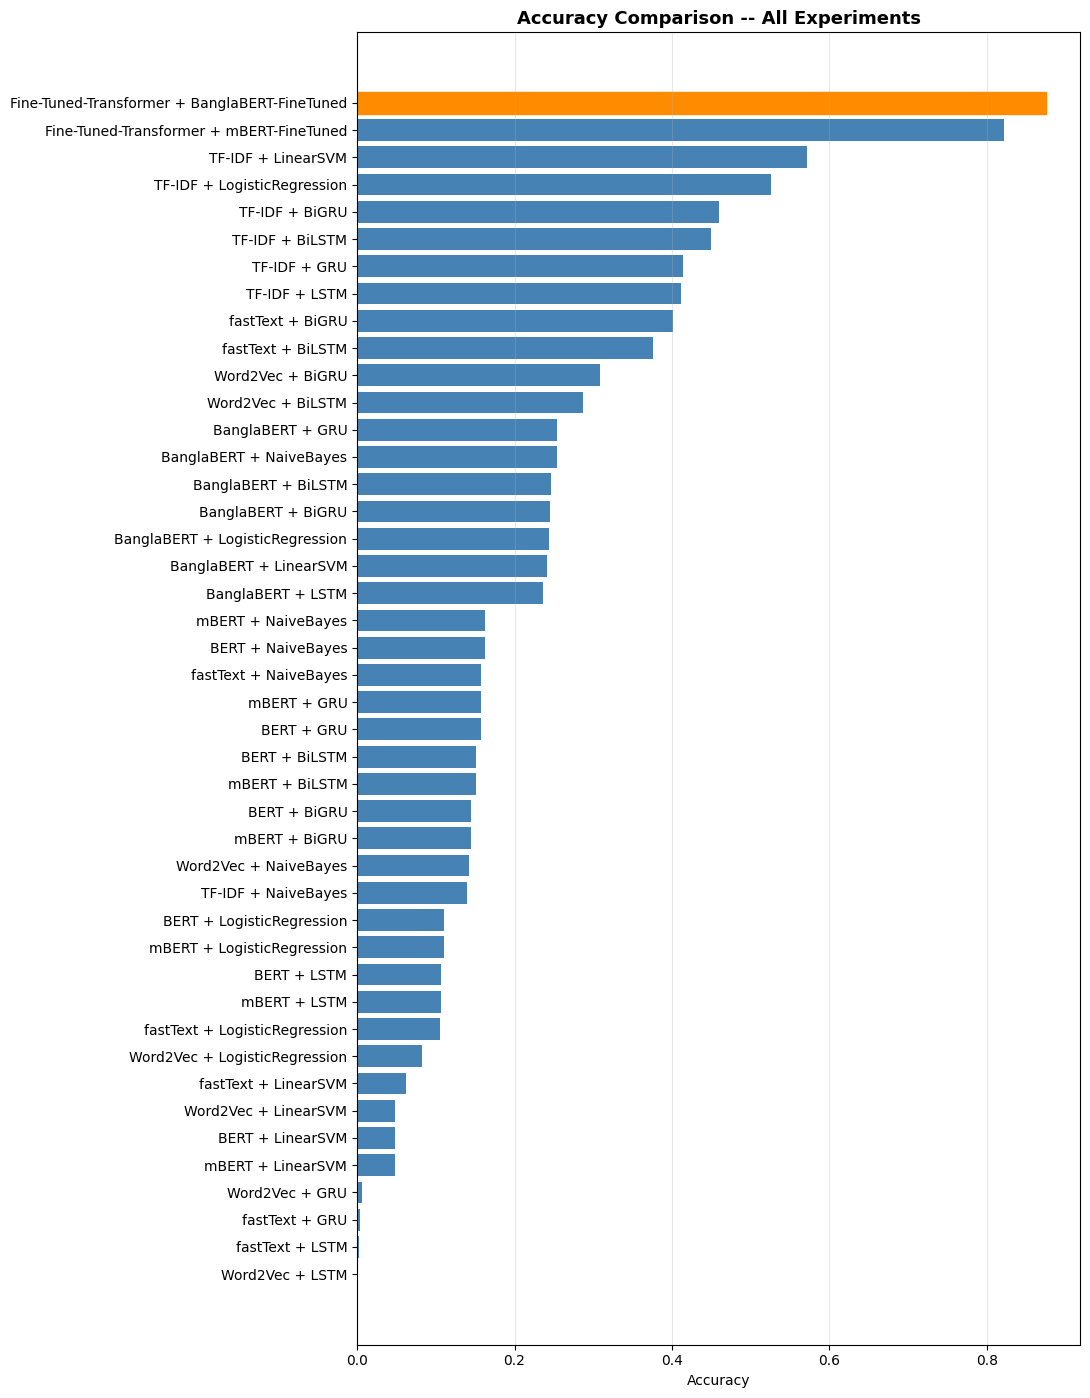

In [37]:
# -----------------------------------------------------------------
# REUSABLE BAR-CHART COMPARISON HELPER
# -----------------------------------------------------------------

def bar_chart_comparison(df_results: pd.DataFrame, metric_col: str, title: str,
                          save_path: str, ascending: bool = False, top_n: int = 44,
                          color: str = 'steelblue'):
    """
    Draws a horizontal bar chart ranking every experiment by `metric_col`.
    Labels combine Embedding + Model for readability.
    """
    plot_df = df_results.copy()
    plot_df = plot_df.dropna(subset=[metric_col])
    plot_df['combo_label'] = plot_df['Embedding'] + ' + ' + plot_df['Model']
    plot_df = plot_df.sort_values(metric_col, ascending=ascending).head(top_n)

    fig_height = max(6, len(plot_df) * 0.32)
    plt.figure(figsize=(11, fig_height))
    bars = plt.barh(plot_df['combo_label'], plot_df[metric_col], color=color)
    plt.gca().invert_yaxis()
    plt.xlabel(metric_col)
    plt.title(title, fontsize=13, fontweight='bold')
    plt.grid(True, axis='x', alpha=0.3)

    # Highlight the best bar (first row after sort)
    if len(bars) > 0:
        bars[0].set_color('darkorange')

    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


# -- Accuracy comparison --------------------------------------------
bar_chart_comparison(final_results_df, 'Accuracy', 'Accuracy Comparison -- All Experiments',
                      os.path.join(CFG.PLOTS_DIR, 'comparison_accuracy.png'))


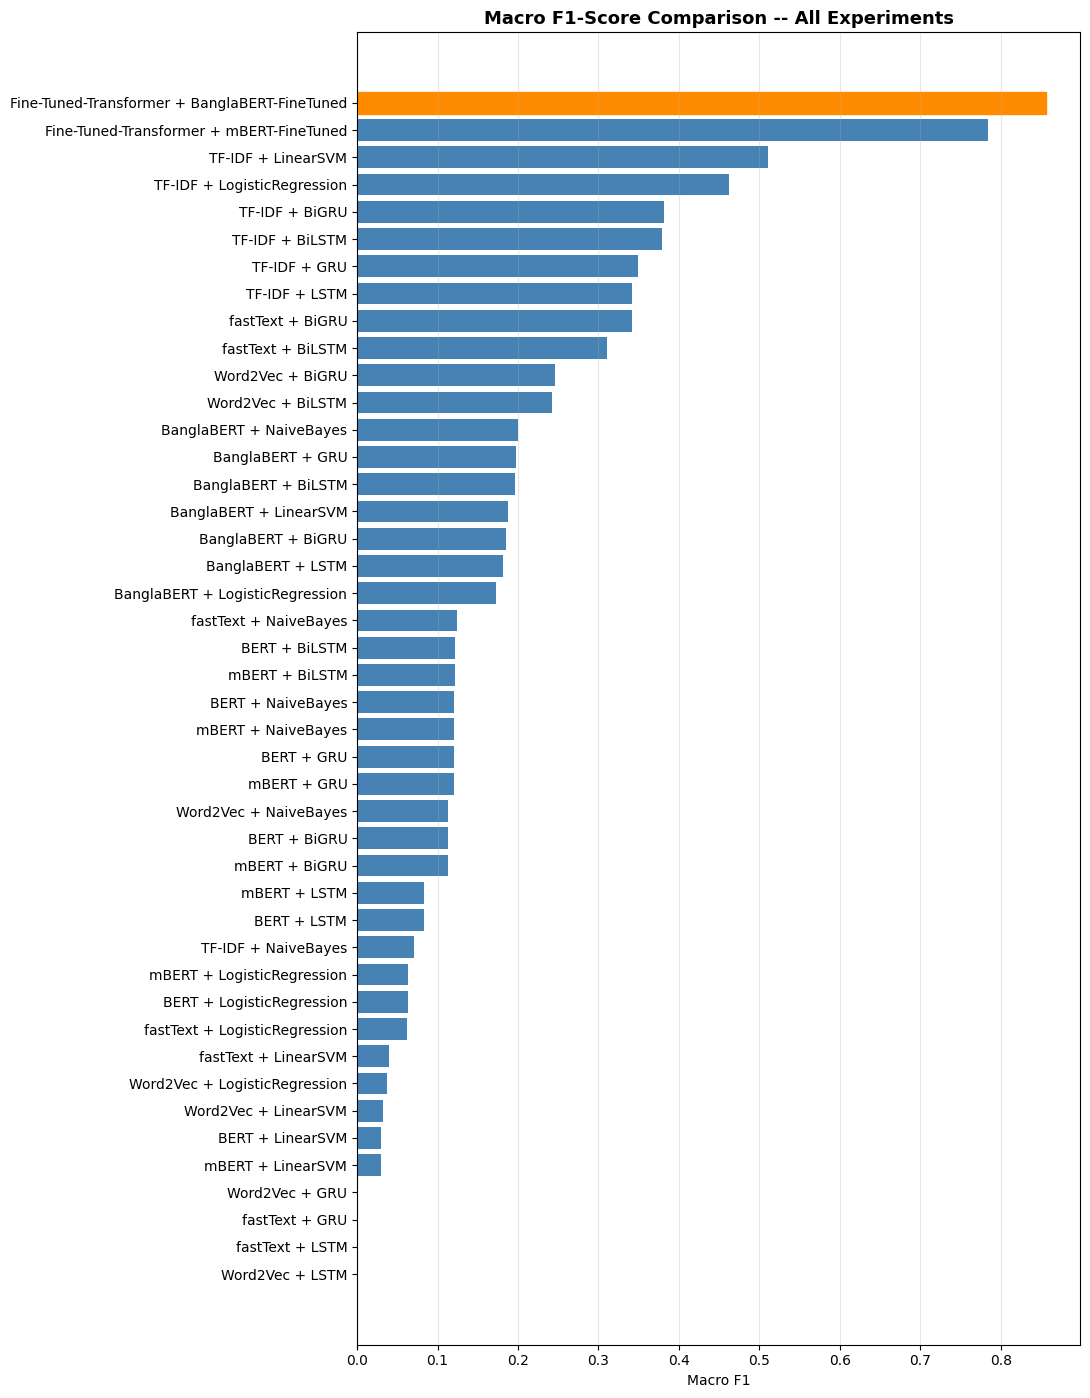

In [38]:
# -- Macro F1 comparison ----------------------------------------------
bar_chart_comparison(final_results_df, 'Macro F1', 'Macro F1-Score Comparison -- All Experiments',
                      os.path.join(CFG.PLOTS_DIR, 'comparison_macro_f1.png'))


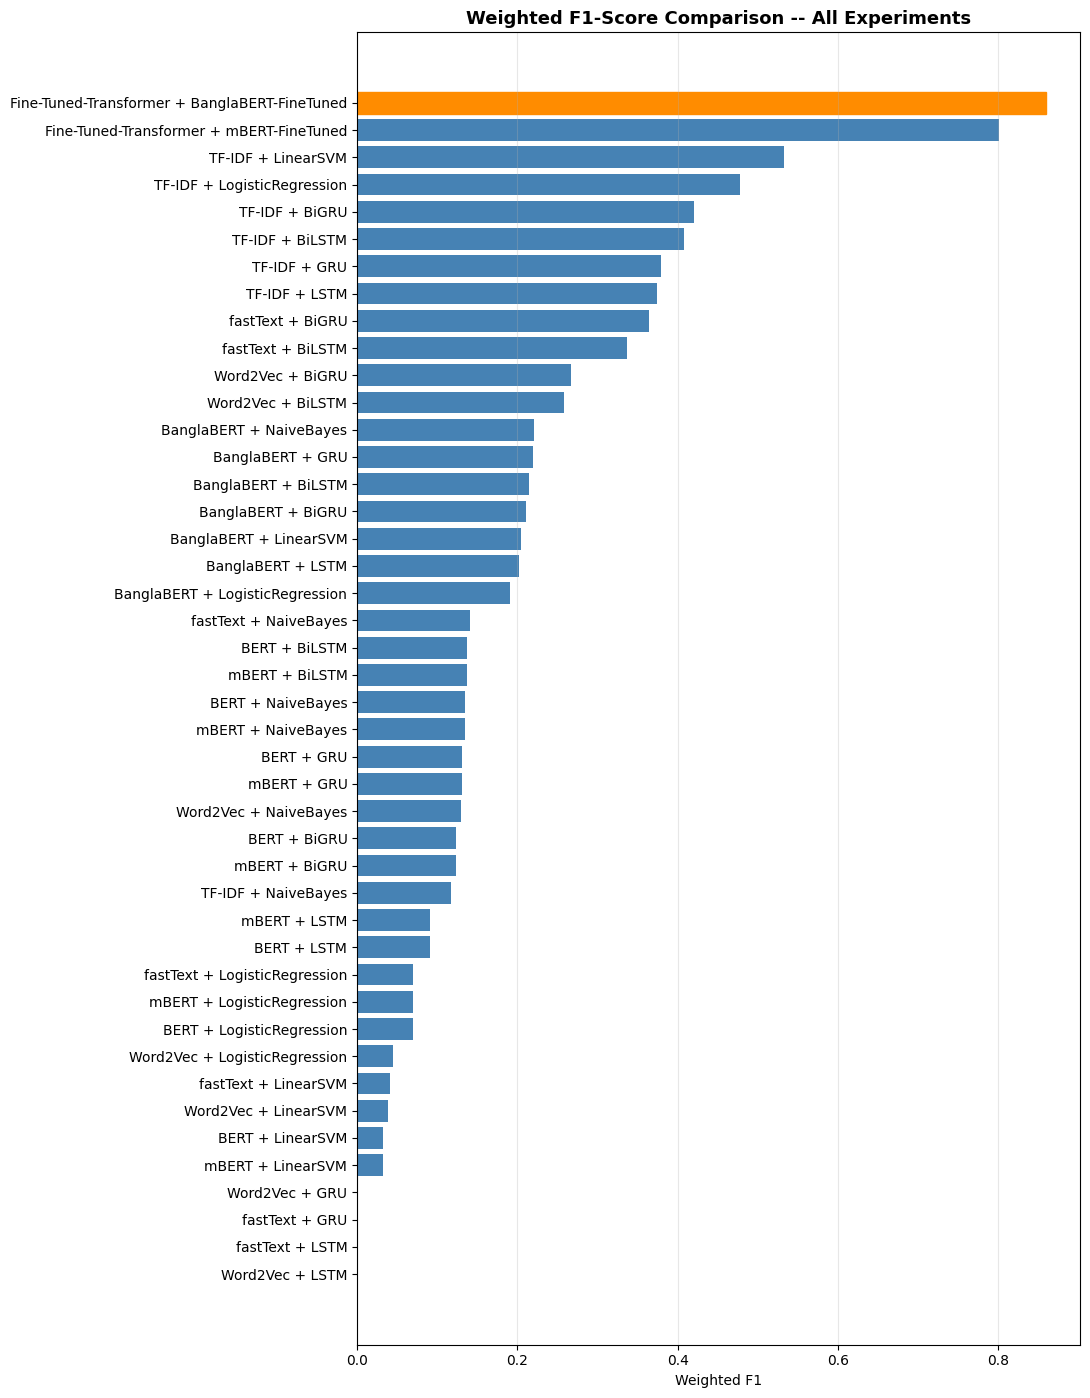

In [39]:
# -- Weighted F1 comparison ---------------------------------------------
bar_chart_comparison(final_results_df, 'Weighted F1', 'Weighted F1-Score Comparison -- All Experiments',
                      os.path.join(CFG.PLOTS_DIR, 'comparison_weighted_f1.png'))


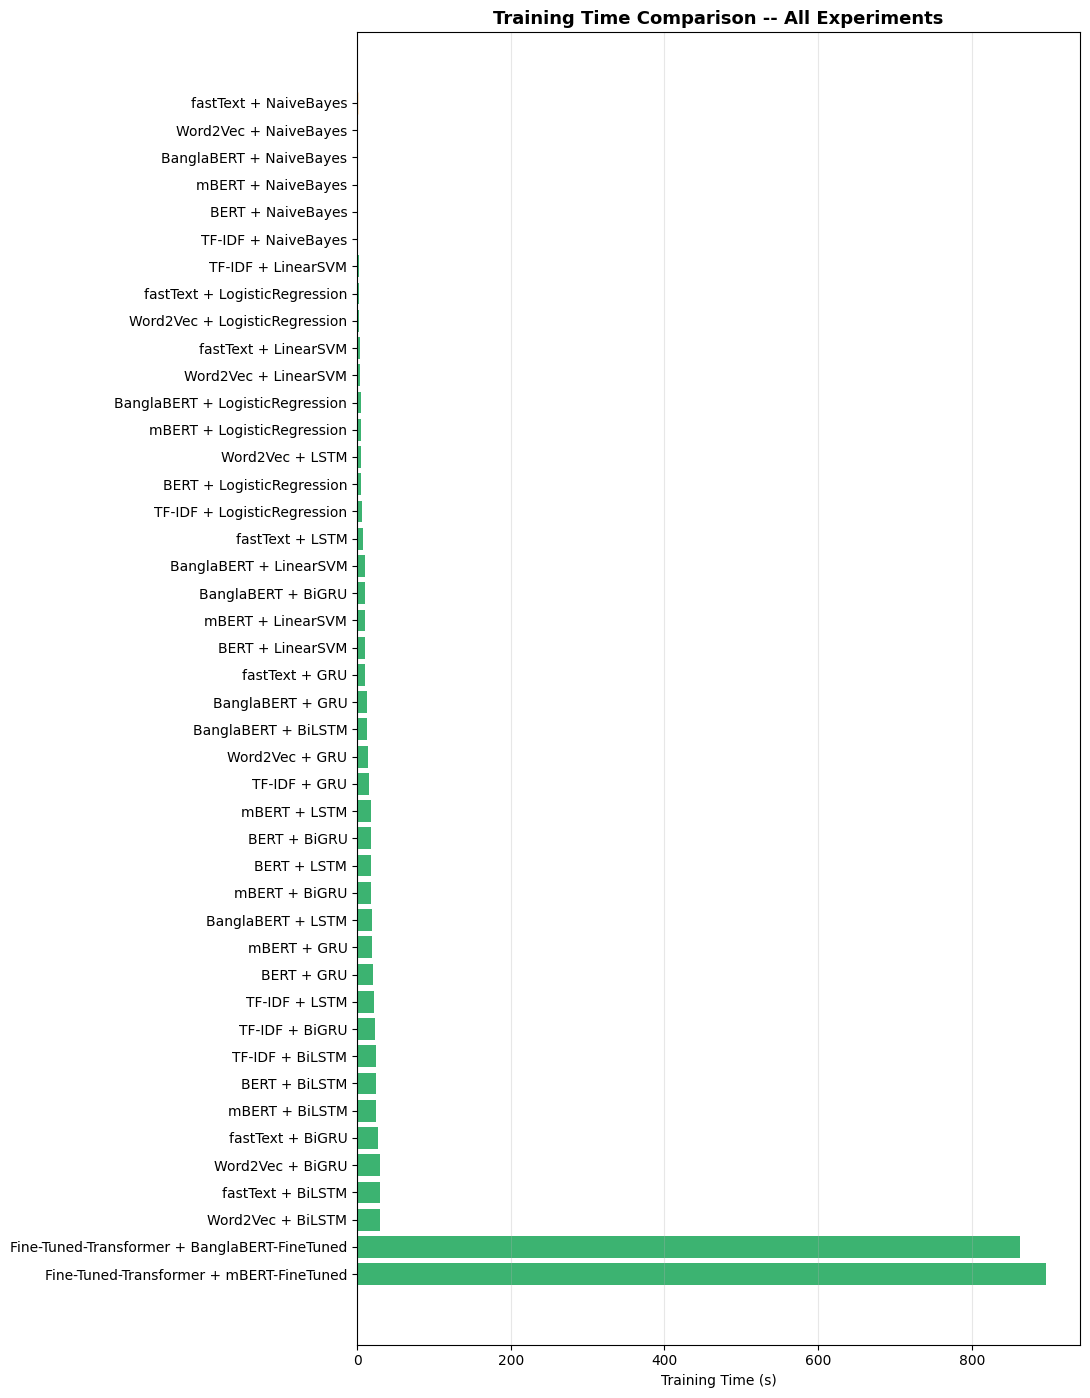

In [40]:
# -- Training Time comparison (lower is better -> ascending sort) -------
bar_chart_comparison(final_results_df, 'Training Time (s)', 'Training Time Comparison -- All Experiments',
                      os.path.join(CFG.PLOTS_DIR, 'comparison_training_time.png'),
                      ascending=True, color='mediumseagreen')


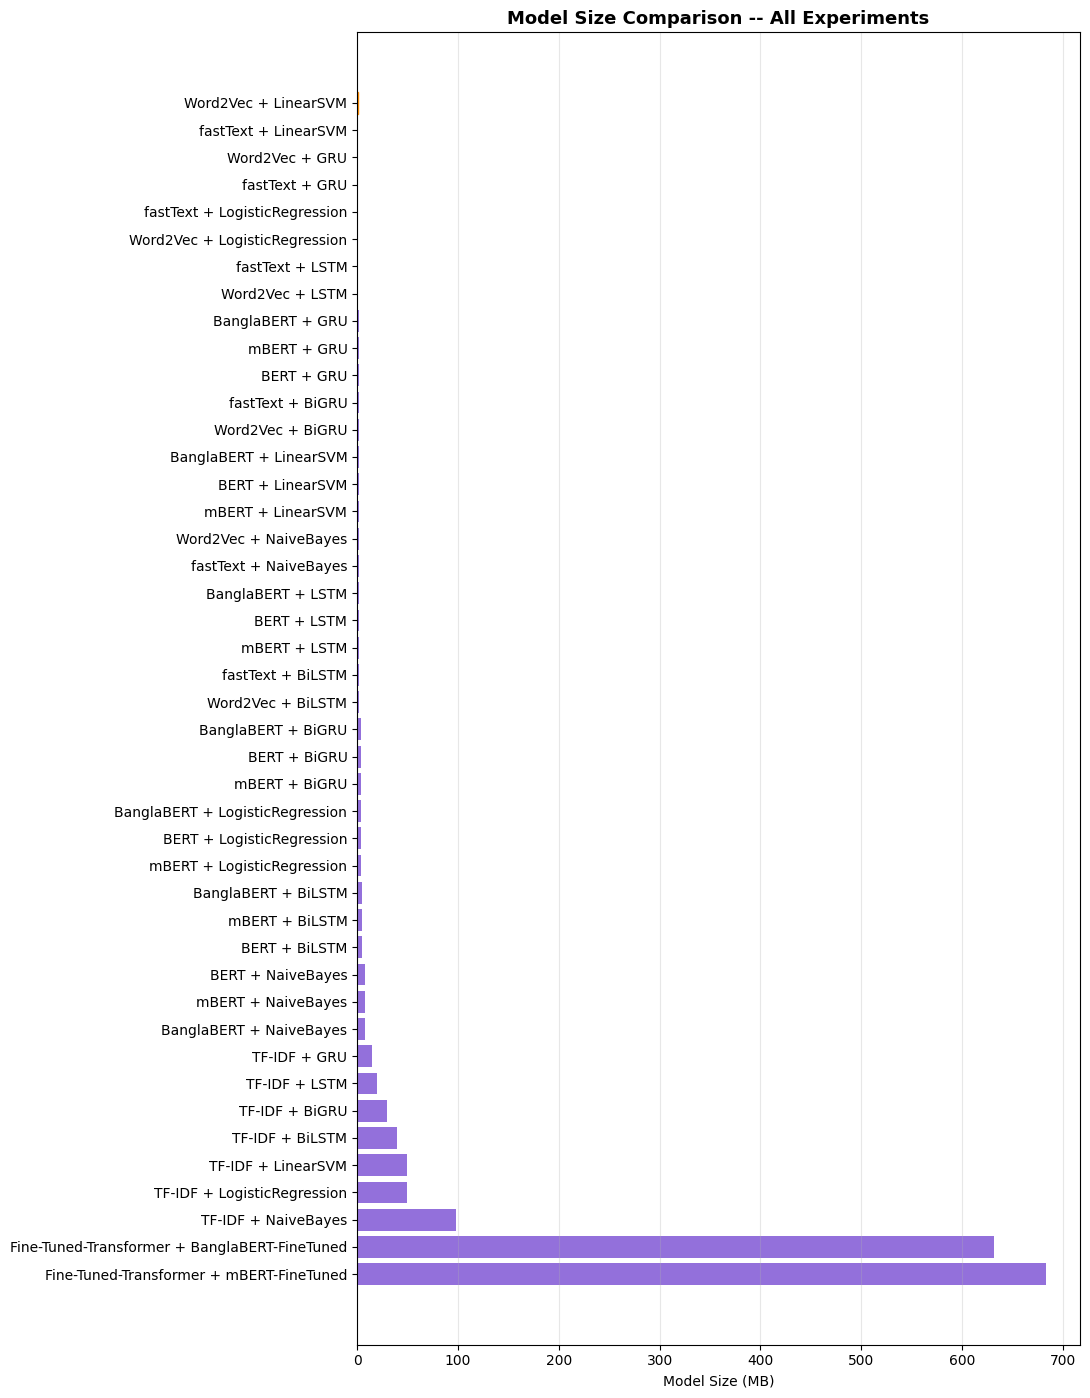

In [41]:
# -- Model Size comparison (lower is better -> ascending sort) -----------
bar_chart_comparison(final_results_df, 'Model Size (MB)', 'Model Size Comparison -- All Experiments',
                      os.path.join(CFG.PLOTS_DIR, 'comparison_model_size.png'),
                      ascending=True, color='mediumpurple')


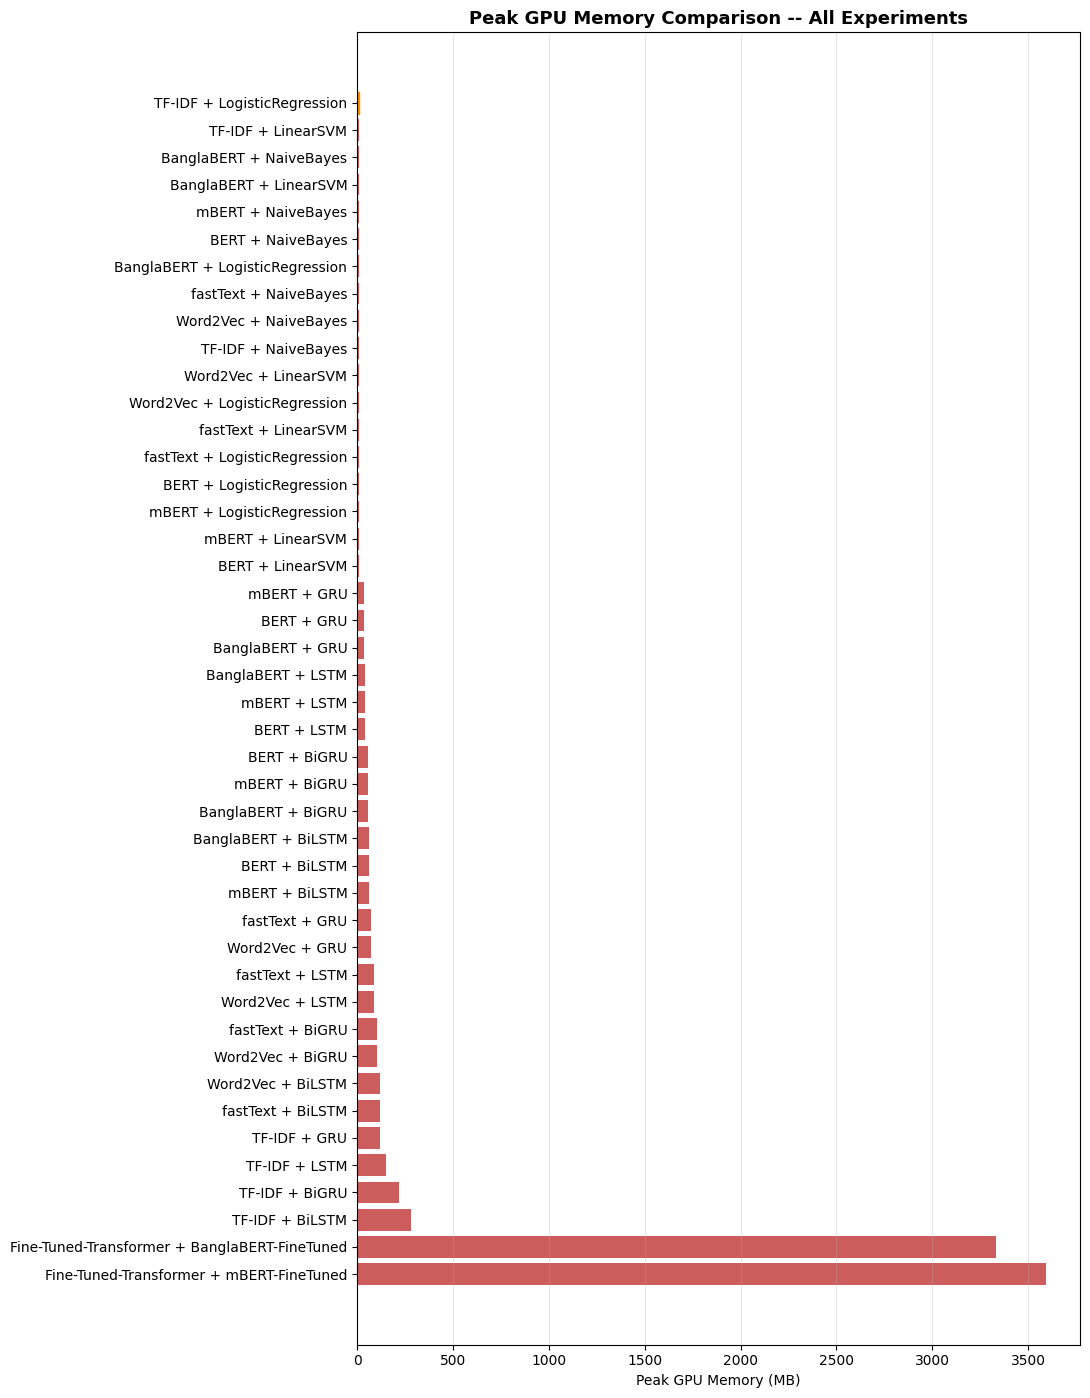

In [42]:
# -- GPU Memory comparison (lower is better -> ascending sort) -----------
bar_chart_comparison(final_results_df, 'Peak GPU Memory (MB)', 'Peak GPU Memory Comparison -- All Experiments',
                      os.path.join(CFG.PLOTS_DIR, 'comparison_gpu_memory.png'),
                      ascending=True, color='indianred')


### 16.3 — All-Metrics Heatmap

A single heatmap with one row per experiment and one column per key metric
(normalized 0-1 per column so metrics on very different scales -- e.g. Accuracy vs.
Training Time -- are visually comparable side by side).


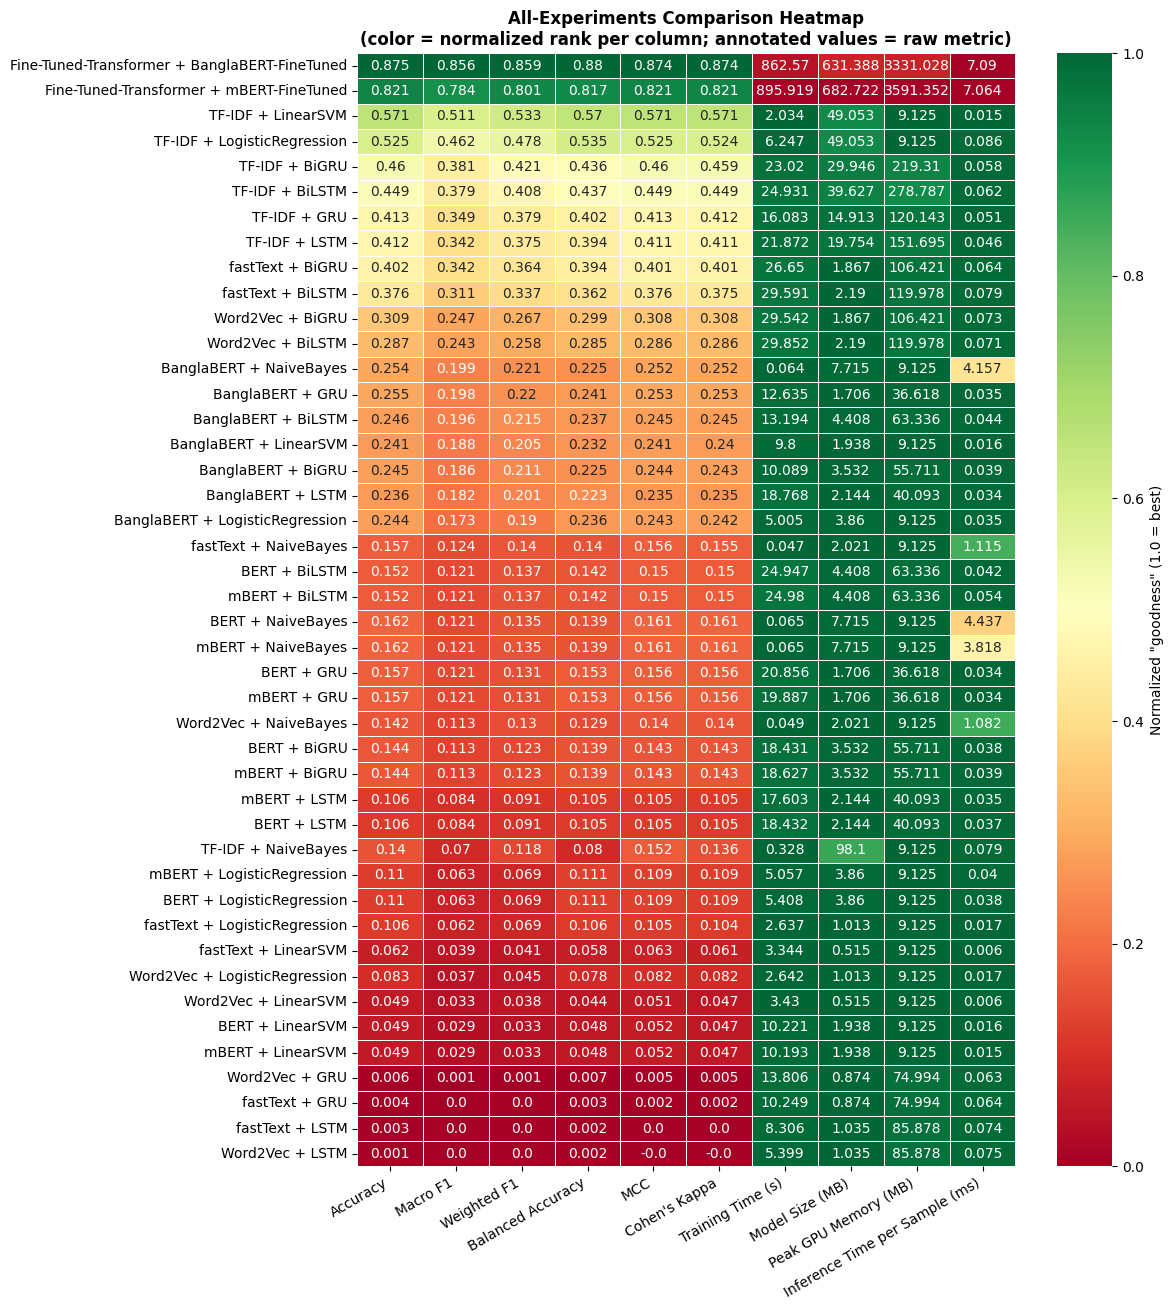

Heatmap saved to: /kaggle/working/plots/comparison_heatmap_all_metrics.png


In [43]:
# -----------------------------------------------------------------
# ALL-EXPERIMENTS HEATMAP
#
# Min-max normalizes each metric column to [0, 1] so metrics with very
# different natural scales can be compared visually in one figure.
# For "lower is better" metrics (time, size, memory) we invert the
# normalization so darker/brighter consistently means "better" --
# this is noted in the plot title.
# -----------------------------------------------------------------

heatmap_metrics_higher_better = ['Accuracy', 'Macro F1', 'Weighted F1', 'Balanced Accuracy', 'MCC', "Cohen's Kappa"]
heatmap_metrics_lower_better  = ['Training Time (s)', 'Model Size (MB)', 'Peak GPU Memory (MB)', 'Inference Time per Sample (ms)']
heatmap_metrics = heatmap_metrics_higher_better + heatmap_metrics_lower_better

heatmap_df = final_results_df[['Embedding', 'Model'] + heatmap_metrics].copy()
heatmap_df['combo_label'] = heatmap_df['Embedding'] + ' + ' + heatmap_df['Model']
heatmap_df = heatmap_df.set_index('combo_label')[heatmap_metrics]

normalized = heatmap_df.copy()
for col in heatmap_metrics_higher_better:
    col_min, col_max = heatmap_df[col].min(), heatmap_df[col].max()
    normalized[col] = (heatmap_df[col] - col_min) / (col_max - col_min + 1e-9)
for col in heatmap_metrics_lower_better:
    col_min, col_max = heatmap_df[col].min(), heatmap_df[col].max()
    # Inverted: lower raw value -> higher normalized "goodness" score
    normalized[col] = 1 - (heatmap_df[col] - col_min) / (col_max - col_min + 1e-9)

fig_height = max(10, len(normalized) * 0.3)
plt.figure(figsize=(12, fig_height))
sns.heatmap(normalized, annot=heatmap_df.round(3), fmt='', cmap='RdYlGn',
            linewidths=0.5, cbar_kws={'label': 'Normalized "goodness" (1.0 = best)'})
plt.title('All-Experiments Comparison Heatmap\n'
          '(color = normalized rank per column; annotated values = raw metric)',
          fontsize=12, fontweight='bold')
plt.xlabel('')
plt.ylabel('')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(os.path.join(CFG.PLOTS_DIR, 'comparison_heatmap_all_metrics.png'), dpi=150, bbox_inches='tight')
plt.show()

print('Heatmap saved to:', os.path.join(CFG.PLOTS_DIR, 'comparison_heatmap_all_metrics.png'))


## 💾 Step 17: Export Everything (CSV, Excel, Markdown, LaTeX, Artifacts)

Final exports, all driven by the single `results_store` object built incrementally
throughout the notebook -- no separate table-construction logic here, just calls to
the export methods defined in Step 9.

Produces:
- `results.csv`, `results.xlsx` (with the best row highlighted), `results.md`,
  `results.tex` (thesis-ready LaTeX table)
- `classification_reports/` — one `.txt` per experiment (already written incrementally)
- `saved_models/` — one file/folder per experiment (already written incrementally)
- `plots/` — training curves, ROC/PR curves, comparison charts (already written incrementally)
- `confusion_matrices/` — one `.png` + `.npy` per experiment (already written incrementally)


In [44]:
# -----------------------------------------------------------------
# RUN ALL EXPORTS
# -----------------------------------------------------------------

results_store.export_csv(CFG.RESULTS_CSV, sort_by='Macro F1')
results_store.export_excel(CFG.RESULTS_XLSX, sort_by='Macro F1')
results_store.export_markdown(CFG.RESULTS_MD, sort_by='Macro F1')
results_store.export_latex(
    CFG.RESULTS_TEX, sort_by='Macro F1',
    caption='Bangla Word Sense Disambiguation: Embedding x Model Comparison Results'
)

print('\nAll exports complete!')
print(f'   CSV:      {CFG.RESULTS_CSV}')
print(f'   Excel:    {CFG.RESULTS_XLSX}')
print(f'   Markdown: {CFG.RESULTS_MD}')
print(f'   LaTeX:    {CFG.RESULTS_TEX}')

print('\nArtifact directories:')
for label, path in [
    ('Classification reports', CFG.REPORTS_DIR),
    ('Saved models', CFG.SAVED_MODELS_DIR),
    ('Plots', CFG.PLOTS_DIR),
    ('Confusion matrices', CFG.CM_DIR),
]:
    n_files = len(os.listdir(path)) if os.path.isdir(path) else 0
    print(f'   {label:24s}: {path}  ({n_files} files)')


Saved CSV: /kaggle/working/results.csv
Saved Excel: /kaggle/working/results.xlsx
Saved Markdown: /kaggle/working/results.md
Saved LaTeX: /kaggle/working/results.tex
   NOTE: \rowcolor requires \usepackage{colortbl} or \usepackage{xcolor}[table] in your LaTeX preamble.

All exports complete!
   CSV:      /kaggle/working/results.csv
   Excel:    /kaggle/working/results.xlsx
   Markdown: /kaggle/working/results.md
   LaTeX:    /kaggle/working/results.tex

Artifact directories:
   Classification reports  : /kaggle/working/classification_reports  (44 files)
   Saved models            : /kaggle/working/saved_models  (44 files)
   Plots                   : /kaggle/working/plots  (121 files)
   Confusion matrices      : /kaggle/working/confusion_matrices  (88 files)


### 17.1 — Zip Everything for Easy Download


In [45]:
# -----------------------------------------------------------------
# ZIP ALL ARTIFACTS FOR EASY DOWNLOAD FROM KAGGLE
# -----------------------------------------------------------------

import zipfile

ZIP_PATH = '/kaggle/working/bangla_wsd_benchmark_all_artifacts.zip'

with zipfile.ZipFile(ZIP_PATH, 'w', zipfile.ZIP_DEFLATED) as zf:
    for result_file in [CFG.RESULTS_CSV, CFG.RESULTS_XLSX, CFG.RESULTS_MD, CFG.RESULTS_TEX]:
        if os.path.exists(result_file):
            zf.write(result_file, os.path.basename(result_file))
    for dir_path, arc_prefix in [
        (CFG.REPORTS_DIR, 'classification_reports'),
        (CFG.PLOTS_DIR, 'plots'),
        (CFG.CM_DIR, 'confusion_matrices'),
    ]:
        for root, _, files in os.walk(dir_path):
            for fname in files:
                full_path = os.path.join(root, fname)
                rel_path = os.path.join(arc_prefix, os.path.relpath(full_path, dir_path))
                zf.write(full_path, rel_path)

print(f'All artifacts zipped to: {ZIP_PATH}')
print(f'   Size: {os.path.getsize(ZIP_PATH) / (1024**2):.1f} MB')
print('   (saved_models/ is NOT included in the zip -- model files can be large; '
      'they remain available directly under /kaggle/working/saved_models/)')


All artifacts zipped to: /kaggle/working/bangla_wsd_benchmark_all_artifacts.zip
   Size: 13.5 MB
   (saved_models/ is NOT included in the zip -- model files can be large; they remain available directly under /kaggle/working/saved_models/)


## 📝 Step 18: Summary & Discussion

### What this notebook produced

- **44 experiments**, all sharing the identical preprocessing pipeline, word-specific
  label space (`target_word + sense_gloss`), and stratified 70/15/15 train/val/test
  split from your original notebook, so every number in the table above is directly
  comparable to every other number. (Run the cell below for the exact class count and
  dataset sizes for this run.)
- A complete metric suite (Accuracy, Macro/Weighted Precision/Recall/F1, Balanced
  Accuracy, MCC, Cohen's Kappa, ROC-AUC where applicable), full timing/memory/size
  instrumentation, confusion matrices, training curves, and ROC/PR curves for every
  experiment.
- Publication-ready exports in CSV, Excel (best row highlighted), Markdown, and
  LaTeX, plus a single zip archive of all plots and reports.

### Honest limitations to mention in your thesis write-up

1. **Class sparsity.** With several hundred classes and roughly 10 samples per class
   on average, this is a genuinely hard classification setting for classical ML models
   trained from scratch (no pretraining). Expect the frozen/fine-tuned transformer
   rows to outperform classical-ML-on-shallow-embeddings by a wide margin -- that gap
   is itself a legitimate and interesting finding for a WSD benchmark, not a bug.
2. **"BERT" vs "mBERT" embedding rows.** Both frozen-CLS-embedding rows use the same
   underlying `bert-base-multilingual-cased` checkpoint (see the note in the title
   cell) because a Bangla-only "BERT" embedding using an English-only checkpoint would
   not be meaningful. Expect these two rows to be close to each other; that is expected
   and should be called out explicitly when you discuss the table, not hidden.
3. **Sequence models on non-sequential embeddings.** LSTM/GRU/BiLSTM/BiGRU applied to
   TF-IDF or to BERT/mBERT/BanglaBERT *frozen CLS vectors* only see a sequence of
   length 1 (Step 12), so they are mathematically closer to small feedforward networks
   for those 16 of the 24 sequence-model experiments. Word2Vec and fastText (8 of the
   24) use genuine token sequences. This is worth a sentence in your methodology
   section so a reader doesn't assume all 24 are "true" sequence-model results.
4. **ROC-AUC / PR curves** are computed one-vs-rest over the full label space and are
   most informative for the most frequent classes (plotted explicitly); they are
   somewhat noisy estimates for the rarest classes given how few test examples each
   one has.

### Reference table acknowledgement

The comparison-table presentation style (columns, sorting by F1, bolding the best
row) follows the structure of the reference PDF you provided for a hate-speech
classification study. No code, numbers, or results from that PDF appear anywhere
above -- every value in `results.csv` / `results.xlsx` / `results.md` / `results.tex`
was generated by the experiments run in this notebook, on your Bangla WSD dataset.


In [46]:
# -----------------------------------------------------------------
# RUN-SPECIFIC SUMMARY STATISTICS
# -----------------------------------------------------------------

print('=' * 70)
print('RUN SUMMARY')
print('=' * 70)
print(f'Total experiments completed:     {len(results_store.rows)} / 44 expected')
print(f'Number of classes (word+sense):  {NUM_CLASSES}')
print(f'Number of distinct target words: {df["target_word"].nunique()}')
print(f'Train / Val / Test sizes:        {len(train_df)} / {len(val_df)} / {len(test_df)}')
print(f'Average samples per class:       {len(df) / NUM_CLASSES:.1f}')
print('=' * 70)

n_classical = sum(1 for r in results_store.rows if r['Model'] in CFG.CLASSICAL_MODELS)
n_sequence  = sum(1 for r in results_store.rows if r['Model'] in CFG.SEQUENCE_MODELS)
n_finetuned = sum(1 for r in results_store.rows if r['Embedding'] == 'Fine-Tuned-Transformer')
print('\nBreakdown:')
print(f'   Classical ML experiments:        {n_classical} / 18')
print(f'   Sequence DL experiments:         {n_sequence} / 24')
print(f'   Fine-tuned transformer runs:     {n_finetuned} / 2')

if len(results_store.rows) < 44:
    missing = []
    for emb in CFG.EMBEDDINGS:
        for m in CFG.CLASSICAL_MODELS + CFG.SEQUENCE_MODELS:
            if not results_store.already_has(emb, m):
                missing.append(f'{emb} + {m}')
    for m in CFG.FINETUNE_MODELS:
        if not results_store.already_has('Fine-Tuned-Transformer', m):
            missing.append(f'Fine-Tuned-Transformer + {m}')
    if missing:
        print(f'\nWARNING: {len(missing)} experiment(s) did not complete successfully:')
        for m in missing:
            print(f'   - {m}')
        print('Re-running the notebook will automatically skip completed experiments '
              'and retry only the missing ones.')
else:
    print('\nAll 44 experiments completed successfully!')


RUN SUMMARY
Total experiments completed:     44 / 44 expected
Number of classes (word+sense):  657
Number of distinct target words: 179
Train / Val / Test sizes:        5166 / 1107 / 1108
Average samples per class:       11.2

Breakdown:
   Classical ML experiments:        18 / 18
   Sequence DL experiments:         24 / 24
   Fine-tuned transformer runs:     2 / 2

All 44 experiments completed successfully!
